# Spatial Contrast vs LNP models on Hoefling et al., 2024

Compares LNP, LN and Spatial Contrast (SC) models fitted to the hoefling_2024 low-res natural movies, and how much the
results depend on the criterion each model is selected with on the validation set.

| model | what is learned |
|---|---|
| **LNP colour (Table 2)** | reference: the manuscript's Table 2 LNP (`model_checkpoints/2026-03-09`): one spatial filter per cell and channel, current frame only |
| **LNP grey lag 0** | reference: one free spatial filter per cell, current frame only (published `hoefling_2024_lnp_low_res_grey_scale`) |
| **LNP colour lag 30** | one free spatial filter per cell and channel (green, UV), each channel with its own 31-frame temporal kernel |
| **LNP grey lag 30** | one free spatial filter x one 31-frame temporal kernel per cell (current frame and the 30 before it) |
| **LN Gaussian** | the SC model with `w` fixed at 0: a Gaussian spatial filter masked at 1.5 sigma, a temporal filter, and a softplus nonlinearity |
| **SC** | as LN Gaussian, plus the local spatial contrast term with weight `w` |

Apart from the colour models, green and UV are averaged inside the core. The two lag-30 LNPs are regularised alike:
spatial smoothness 3e4, temporal smoothness 1e3, L1 weight 1. The temporal smoothness is needed with a random start:
without it, the parts of each temporal kernel that the natural movies leave unconstrained keep their random starting
values, and the kernels end up as jagged as white noise. 1e3 is the smallest weight of a small pilot
(3e2, 1e3, 3e3, 1e4, selected on validation correlation) that made them smooth, at a cost of 0.002 (colour) and 0.005
(grey) in validation correlation against no smoothing. The LN and SC models have no temporal penalty, and their
temporal filters keep part of their random start (see "How far the learned filters moved").

**Initialisation.** The trained models start from random filters, so that none inherits another model's fit. The
LNPs' spatial filters start xavier-normal and their temporal kernels i.i.d. uniform in (-a, a) per tap, a = sqrt(3/T).
The LN and SC models start every cell from the same isotropic Gaussian (sigma 1.5 px, at the centre of the stimulus)
and a random temporal filter drawn the same way, and learn the Gaussian (centre, widths, orientation) and the temporal
filter together with the nonlinearity. At lag 0 the temporal filter is a single frame normalised to unit length, so it
starts as a random sign.

**Selection criterion.** Each trained model was fitted twice, identical except for the validation metric that drives
early stopping, the checkpoint and the learning-rate schedule (`model_selection=val_loss` or
`model_selection=val_correlation`):

- **val loss**: the validation Poisson loss, i.e. the training objective without its regularisers. The correlation
  reported below then plays no part in fitting or selecting the model.
- **val corr**: the validation correlation. This selects on (the validation version of) the metric reported below.

Each model's learning rate (for LN and SC, the filters' learning rate) was chosen once, as the value with the highest
validation correlation in a small pilot, and both runs use it. Under both criteria, neither early stopping nor the
learning-rate schedule acts in the first 30 epochs (`selection_warmup_epochs`): with a random start and a strong
temporal penalty, the validation loss first rises while the penalty smooths the kernels, and without the warm-up the
val-loss runs stopped at epoch 10 with their epoch-0 checkpoint. No choice looked at the test set.

"Lag" follows the manuscript: the frames the model consumes before its first prediction. Every model here drops the
first 30 frames of each prediction (lag-0 models by cutting them, lag-30 models by filtering over them), so every
metric below is computed on the same frames, as in Table 2.

The notebook reports test correlation and FEVe (fraction of explainable variance explained, using the three test
repeats) with the manuscript's Table 2 protocol, compares the two selection criteria and the filters, plots predictions
against the recorded responses, and compares the contrast weight `w` of the lag-0 and lag-30 SC models.

**Prerequisites.** Apart from the published LNPs, the models are the `selection_v3` training runs, one
`openretina train` each (trained on a cluster; seed 42, `trainer.max_epochs=300`):

1. LNP grey lag 30: `--config-name hoefling_2024_core_readout_low_res_lnp_grey_separable
   model.readout.temporal_kernel_size=31 model.core.cut_first_n_frames=0 +model.readout.temporal_init=random
   model.learning_rate=5e-3 model.readout.smooth_weight_temporal=1e3`
2. LNP colour lag 30: `--config-name hoefling_2024_core_readout_low_res_lnp_separable model.learning_rate=1e-2`
3. LN/SC: `--config-name hoefling_2024_sc_low_res_lnp_grey model.filter_init=random model.learn_filters=true
   model.sigma_contour=1.5 model.filter_learning_rate=1e-2 model.temporal_filter_length=31` (lag 30, or `=1` for
   lag 0), adding `model.learn_contrast_weight=false` for LN.

each once with `model_selection=val_loss` and once with `model_selection=val_correlation`.

4. Optional, for the section on the current-frame weight:
   - the random-init grey LNP without temporal smoothness (`selection_v1`): command 1 with
     `model.readout.smooth_weight_temporal=0 model_selection=val_correlation selection_warmup_epochs=0`;
   - the earlier lag-30 LNP, whose temporal kernel starts as a delta on the current frame: command 1 with
     `model.readout.smooth_weight_temporal=0 model_selection=val_correlation selection_warmup_epochs=0`, without
     `+model.readout.temporal_init=random` and at the default learning rate;
   - its variants: with `+model.readout.temporal_init=uniform`, with `data_io.responses.response_delay_frames=D`
     (D = 3, 6, 9), and with `+data_io.responses.trace_type=preprocessed`.

Point `SELECTION_RUNS` and `DIAGNOSTIC_LNPS` below at the run directories. Runs that do not exist are skipped.

# Imports

In [1]:
import copy
import itertools
import logging
import os
import re
from pathlib import Path

import hydra
import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
from einops import rearrange
from scipy.stats import pearsonr, spearmanr

from openretina.data_io.hoefling_2024.dataloaders import natmov_dataloaders_v2
from openretina.data_io.hoefling_2024.responses import filter_responses, make_final_responses
from openretina.data_io.hoefling_2024.stimuli import movies_from_pickle
from openretina.eval.metrics import correlation_numpy, explainable_vs_total_var, feve
from openretina.models.core_readout import load_core_readout_model
from openretina.models.spatial_contrast import SpatialContrastCoreReadout
from openretina.modules.readout.linear_nonlinear_poison import SeparableLNPReadout
from openretina.modules.readout.spatial_contrast_model_readout import (
    LearnableFilterSpatialContrastReadout,
    SpatialContrastReadout,
)
from openretina.utils.file_utils import get_cache_directory, get_local_file_path
from openretina.utils.h5_handling import load_h5_into_dict

matplotlib.rcParams["pdf.fonttype"] = 42
matplotlib.rcParams["ps.fonttype"] = 42
logging.basicConfig(level=logging.WARNING)

%matplotlib inline
%config InlineBackend.figure_format = 'retina'

# Configuration

`MODELS` maps a label to `(kind, location)`: `kind` is `"lnp"` (loaded with `load_core_readout_model`, so the
location can be a published model name or a checkpoint) or `"sc"` (a `SpatialContrastCoreReadout` checkpoint). A
location that is a directory is searched for the `*_final.ckpt` written after testing. Locations can also be
HuggingFace URLs. Spatial Contrast checkpoints store their filters, so they load without anything else.

The trained models enter `MODELS` once per selection criterion, as `<model> · val loss` and `<model> · val corr`.

Set `TRACE_EXPORT_DIR` to a directory to also save a prediction plot for every cell (~3000 files).

In [2]:
REPO = Path("..").resolve()
RUNS = REPO / "openretina_assets" / "runs"
SELECTION_RUNS = RUNS / "selection_v3"
HF_CHECKPOINTS = "https://huggingface.co/datasets/open-retina/open-retina/tree/main/model_checkpoints"

# Trained models: (kind, run directory under SELECTION_RUNS)
TRAINED_MODELS: dict[str, tuple[str, str]] = {
    "LNP colour lag 30": ("lnp", "lnp_colour_t31"),
    "LNP grey lag 30": ("lnp", "lnp_grey_t31"),
    "LN Gaussian lag 0": ("sc", "ln_lag0"),
    "SC lag 0": ("sc", "sc_lag0"),
    "LN Gaussian lag 30": ("sc", "ln_t31"),
    "SC lag 30": ("sc", "sc_t31"),
}
# Selection criterion: the run of a trained model selected with it
CRITERIA = {"val loss": "val_loss", "val corr": "val_correlation"}

MODELS: dict[str, tuple[str, str | Path]] = {
    "LNP colour (Table 2)": ("lnp", f"{HF_CHECKPOINTS}/2026-03-09/hoefling_2024_lnp_low_res.ckpt"),
    "LNP grey lag 0": ("lnp", "hoefling_2024_lnp_low_res_grey_scale"),
}
for name, (kind, directory) in TRAINED_MODELS.items():
    for criterion, run in CRITERIA.items():
        MODELS[f"{name} · {criterion}"] = (kind, SELECTION_RUNS / directory / run)

# Models shown in the filter and trace figures, and compared in the w figures (the summary table uses all of them)
FILTER_MODELS = ["LNP grey lag 0", "SC lag 0 · val loss", "LNP grey lag 30 · val loss", "SC lag 30 · val loss"]
COLOUR_FILTER_MODELS = ["LNP colour lag 30 · val loss", "LNP colour lag 30 · val corr"]
TRACE_MODELS = [
    "LNP colour lag 30 · val loss",
    "LNP grey lag 30 · val loss",
    "LN Gaussian lag 30 · val loss",
    "SC lag 30 · val loss",
]
W_MODELS = ["SC lag 0 · val loss", "SC lag 0 · val corr", "SC lag 30 · val loss", "SC lag 30 · val corr"]
# Reference model for picking example cells
REFERENCE_MODEL = "LNP grey lag 30 · val loss"

# Diagnostic runs for the section on the current-frame weight: the earlier lag-30 LNP, whose temporal kernel starts as
# a delta on the current frame, and that LNP retrained with a uniform temporal init, on delayed responses, and on
# calcium traces. All were selected on validation correlation. They are only used there, not in the metrics.
DIAGNOSTIC_LNPS: dict[str, str | Path] = {
    "current-frame init": RUNS / "lnp_grey_separable_t31" / "tsmooth0",
    "delay 3 frames": RUNS / "lnp_grey_separable_t31_delay" / "d3",
    "delay 6 frames": RUNS / "lnp_grey_separable_t31_delay" / "d6",
    "delay 9 frames": RUNS / "lnp_grey_separable_t31_delay" / "d9",
    "calcium": RUNS / "lnp_grey_separable_t31_calcium",
    "uniform init": RUNS / "lnp_grey_separable_t31_uniform" / "d0",
    "uniform init, delay 6 frames": RUNS / "lnp_grey_separable_t31_uniform" / "d6",
    "uniform init, calcium": RUNS / "lnp_grey_separable_t31_uniform" / "calcium",
    # The random-init LNP of this notebook without its temporal smoothness
    "random init, unsmoothed, val corr": RUNS / "selection_v1" / "lnp_grey_t31" / "val_correlation_lr5e-3",
}

# FEVe is only meaningful for cells whose responses repeat across the three test presentations: with little explainable
# variance, any prediction within the noise level scores FEVe = 1. Such cells are left out of the FEVe statistics.
# 0.15 is the cutoff of the manuscript's Table 2.
MIN_EXPLAINABLE_VARIANCE_RATIO = 0.15

# Optional: export one prediction plot per cell for all cells
TRACE_EXPORT_DIR: str | None = None  # e.g. "../openretina_assets/figures/traces"
TRACE_EXPORT_FORMAT = "png"

FRAME_RATE_HZ = 30
CLIP_LENGTH = 150

device = "cuda" if torch.cuda.is_available() else "cpu"

# Data

The same data pipeline the models were trained with: stimuli, quality-filtered responses, dataloaders.

In [3]:
with hydra.initialize(config_path=os.path.join("..", "configs"), version_base="1.3"):
    cfg = hydra.compose(config_name="hoefling_2024_core_readout_low_res_lnp_grey.yaml")

CACHE_DIR = os.environ.get("OPENRETINA_CACHE_DIRECTORY") or get_cache_directory()
cfg.paths.cache_dir = CACHE_DIR
os.environ["OPENRETINA_CACHE_DIRECTORY"] = CACHE_DIR

movies_dict = movies_from_pickle(get_local_file_path(file_path=cfg.paths.movies_path, cache_folder=cfg.paths.data_dir))
responses_dict = load_h5_into_dict(
    file_path=get_local_file_path(file_path=cfg.paths.responses_path, cache_folder=cfg.paths.data_dir)
)
final_responses = make_final_responses(filter_responses(responses_dict, **cfg.quality_checks), response_type="natural")

dataloaders = natmov_dataloaders_v2(
    neuron_data_dictionary=final_responses,
    movies_dictionary=movies_dict,
    allow_over_boundaries=True,
    batch_size=cfg.dataloader.batch_size,
    train_chunk_size=cfg.dataloader.train_chunk_size,
    validation_clip_indices=cfg.dataloader.validation_clip_indices,
)
sessions = sorted(final_responses)
print(f"{sum(len(final_responses[s].session_kwargs['roi_ids']) for s in sessions)} neurons over {len(sessions)} sessions")

Loading HDF5 file contents:   0%|          | 0/2077 [00:00<?, ?item/s]

Original dataset contains 7863 neurons over 67 fields
 ------------------------------------ 


Dropped 0 fields that did not contain the target cell types (67 remaining)
Overall, dropped 3034 neurons of non-target cell types (-38.59%).
 ------------------------------------ 


Dropped 0 fields with quality indices below threshold (67 remaining)
Overall, dropped 980 neurons over quality checks (-20.29%).
 ------------------------------------ 


Dropped 0 fields with classifier confidences below 0.25
Overall, dropped 705 neurons with classifier confidences below 0.25 (-18.32%).
 ------------------------------------ 
 ------------------------------------ 
Final dataset contains 3144 neurons over 67 fields
Total number of cells dropped: 4719 (-60.02%)


Upsampling natural spikes traces to get final responses.:   0%|          | 0/67 [00:00<?, ?it/s]

Creating movie dataloaders:   0%|          | 0/67 [00:00<?, ?it/s]

3144 neurons over 67 sessions


# Models

In [4]:
def resolve_checkpoint(location: str | Path) -> str | None:
    """A published name, URL or checkpoint path as is; for a run directory, its `_final` checkpoint."""
    if str(location).startswith(("http://", "https://")):
        return str(location)  # downloaded to the cache when loading
    path = Path(location)
    if path.is_dir():
        finals = sorted(path.glob("checkpoints/*_final.ckpt"))
        return str(finals[-1]) if finals else None
    if path.suffix == ".ckpt":
        return str(path) if path.exists() else None
    if isinstance(location, Path):
        return None  # a run directory that does not exist
    return str(location)  # a published model name


models = {}
for label, (kind, location) in MODELS.items():
    checkpoint = resolve_checkpoint(location)
    if checkpoint is None:
        print(f"skipping {label}: nothing at {location}")
        continue
    if kind == "sc":
        model = SpatialContrastCoreReadout.load_from_checkpoint(
            get_local_file_path(checkpoint), map_location=device, weights_only=False
        )
    else:
        model = load_core_readout_model(checkpoint, device)
    models[label] = model.eval()
    assert set(model.readout.keys()) == set(sessions), f"{label} was trained on different sessions"

print(f"loaded {len(models)} models: {list(models)}")
FILTER_MODELS = [m for m in FILTER_MODELS if m in models]
TRACE_MODELS = [m for m in TRACE_MODELS if m in models]
W_MODELS = [m for m in W_MODELS if m in models]
COLOUR_FILTER_MODELS = [m for m in COLOUR_FILTER_MODELS if m in models]
# The two runs of a trained model share a hue, dark for val loss and light for val corr; the references are grey
pair_colours = sns.color_palette("tab20")[2:]
palette = {"LNP colour (Table 2)": "0.15", "LNP grey lag 0": "0.55"}
for name, dark, light in zip(TRAINED_MODELS, pair_colours[::2], pair_colours[1::2]):
    palette[f"{name} · val loss"], palette[f"{name} · val corr"] = dark, light
palette = {label: palette[label] for label in models}

/home/shash/PycharmProjects/open-retina/.venv/lib/python3.12/site-packages/lightning/pytorch/utilities/parsing.py:213: Attribute 'core' is an instance of `nn.Module` and is already saved during checkpointing. It is recommended to ignore them using `self.save_hyperparameters(ignore=['core'])`.
/home/shash/PycharmProjects/open-retina/.venv/lib/python3.12/site-packages/lightning/pytorch/utilities/parsing.py:213: Attribute 'readout' is an instance of `nn.Module` and is already saved during checkpointing. It is recommended to ignore them using `self.save_hyperparameters(ignore=['readout'])`.
/home/shash/PycharmProjects/open-retina/.venv/lib/python3.12/site-packages/lightning/pytorch/utilities/parsing.py:213: Attribute 'loss' is an instance of `nn.Module` and is already saved during checkpointing. It is recommended to ignore them using `self.save_hyperparameters(ignore=['loss'])`.


loaded 14 models: ['LNP colour (Table 2)', 'LNP grey lag 0', 'LNP colour lag 30 · val loss', 'LNP colour lag 30 · val corr', 'LNP grey lag 30 · val loss', 'LNP grey lag 30 · val corr', 'LN Gaussian lag 0 · val loss', 'LN Gaussian lag 0 · val corr', 'SC lag 0 · val loss', 'SC lag 0 · val corr', 'LN Gaussian lag 30 · val loss', 'LN Gaussian lag 30 · val corr', 'SC lag 30 · val loss', 'SC lag 30 · val corr']


# Test predictions, correlation and FEVe

Each model predicts the full 750-frame test movie (five clips) of every session. Correlation is computed against the
response averaged over the three repeats; FEVe against the individual repeats, as in
`eval_hoefling_2024_lnp_grey.ipynb`. Both skip the frames the model cuts at the start. Calibration is the ratio of the
mean prediction to the mean recorded response (1 = the model gets the cell's mean rate right).

In [5]:
predictions: dict[str, dict[str, np.ndarray]] = {label: {} for label in models}
rows = []
for session in sessions:
    responses = final_responses[session]
    by_trial = responses.test_by_trial  # (neurons, time, trials)
    test_movie = dataloaders["test"][session].dataset.movies  # already mirrored for left-eye recordings
    roi_ids = responses.session_kwargs["roi_ids"]
    groups = responses.session_kwargs["group_assignment"]

    for label, model in models.items():
        with torch.no_grad():
            prediction = model(test_movie.to(model.device).unsqueeze(0), data_key=session)
        prediction = prediction.squeeze(0).cpu().numpy()  # (time, neurons)
        predictions[label][session] = prediction
        lag = by_trial.shape[1] - prediction.shape[0]

        targets = rearrange(by_trial, "neurons time trials -> time trials neurons")[lag:]
        explainable_ratio, _ = explainable_vs_total_var(targets)
        feve_per_neuron = feve(targets, prediction)
        corr_per_neuron = correlation_numpy(responses.test_response.T[lag:], prediction, axis=0)
        corr_per_trial = [correlation_numpy(targets[:, i], prediction, axis=0) for i in range(targets.shape[1])]
        calibration = prediction.mean(axis=0) / responses.test_response[:, lag:].mean(axis=1)
        for neuron in range(prediction.shape[1]):
            rows.append(
                {
                    "model": label,
                    "session": session,
                    "neuron": neuron,
                    "roi_id": int(roi_ids[neuron]),
                    "group": int(groups[neuron]),
                    "lag": lag,
                    "explainable_ratio": explainable_ratio[neuron],
                    "correlation": corr_per_neuron[neuron],
                    **{f"correlation_trial_{i}": corr[neuron] for i, corr in enumerate(corr_per_trial)},
                    "feve": feve_per_neuron[neuron],
                    "calibration": calibration[neuron],
                }
            )

metrics = pd.DataFrame(rows)
metrics["reliable"] = metrics["explainable_ratio"] >= MIN_EXPLAINABLE_VARIANCE_RATIO
assert metrics["lag"].nunique() == 1, "models cut different frames"
print(f"all models evaluated on frames {metrics['lag'].iloc[0]}..{by_trial.shape[1] - 1} of the test movie")
n_reliable = metrics.drop_duplicates(["session", "neuron"])["reliable"].sum()
print(f"{n_reliable} of {len(metrics) // len(models)} cells have explainable/total variance >= {MIN_EXPLAINABLE_VARIANCE_RATIO}")

all models evaluated on frames 30..749 of the test movie
2408 of 3144 cells have explainable/total variance >= 0.15


## Table 2 protocol

The numbers as the manuscript's Table 2 reports them, over the reliable cells (explainable/total variance >= 0.15):
**Avg** is the correlation with the response averaged over the three repeats; **Indiv** the correlation with single
repeats, averaged over cells for each repeat, then mean ± standard deviation over the three repeats; **FEVe** is clipped
at 0 per cell, then averaged. `FEVe = 0` is the fraction of reliable cells at that floor.

The second table gives paired differences between models selected with the same criterion (the two criteria are
compared in [their own section](#Selection-criterion:-validation-loss-vs-validation-correlation)), over the same
cells, with 95% confidence intervals from resampling the 67
recording fields (sessions), since cells of one field share a stimulus and a recording.

In [6]:
TABLE_MODELS = [m for m in MODELS if m in models]
trial_columns = [c for c in metrics.columns if c.startswith("correlation_trial_")]
reliable_cells = metrics[metrics["reliable"]]
table2 = pd.DataFrame(
    {
        model: {
            "Avg": cells["correlation"].mean(),
            "Indiv": "{:.3f} ± {:.3f}".format(cells[trial_columns].mean().mean(), cells[trial_columns].mean().std(ddof=0)),
            "FEVe": cells["feve"].mean(),
            "FEVe = 0": (cells["feve"] <= 0).mean(),
            "median calibration": cells["calibration"].median(),
        }
        for model, cells in reliable_cells.groupby("model", sort=False)
    }
).T.loc[TABLE_MODELS]
numeric = ["Avg", "FEVe", "FEVe = 0", "median calibration"]
table2[numeric] = table2[numeric].astype(float)
print(f"{reliable_cells.drop_duplicates(['session', 'neuron']).shape[0]} reliable cells")
table2.round(3)

2408 reliable cells


,Avg,Indiv,FEVe,FEVe = 0,median calibration
LNP colour (Table 2),0.293,0.235 ± 0.020,0.029,0.845,1.206
LNP grey lag 0,0.294,0.233 ± 0.024,0.079,0.542,1.082
LNP colour lag 30 · val loss,0.440,0.352 ± 0.017,0.242,0.291,1.037
LNP colour lag 30 · val corr,0.440,0.352 ± 0.017,0.241,0.297,1.034
LNP grey lag 30 · val loss,0.369,0.295 ± 0.017,0.196,0.283,1.044
LNP grey lag 30 · val corr,0.370,0.296 ± 0.017,0.196,0.291,1.045
LN Gaussian lag 0 · val loss,0.274,0.217 ± 0.022,0.112,0.429,1.055
LN Gaussian lag 0 · val corr,0.267,0.212 ± 0.021,0.103,0.397,1.046
SC lag 0 · val loss,0.274,0.217 ± 0.022,0.117,0.412,1.045
SC lag 0 · val corr,0.276,0.219 ± 0.022,0.117,0.419,1.046


In [7]:
def paired_difference(a: str, b: str, value: str, n_resamples: int = 5000) -> tuple[float, float, float]:
    """Mean of b - a over reliable cells, with a 95% CI from resampling sessions."""
    wide = reliable_cells.pivot_table(index=["session", "neuron"], columns="model", values=value)
    difference = (wide[b] - wide[a]).rename("difference").reset_index()
    per_session = difference.groupby("session")["difference"].agg(["sum", "count"])
    resampled = np.random.default_rng(0).integers(0, len(per_session), (n_resamples, len(per_session)))
    bootstrap = per_session["sum"].values[resampled].sum(1) / per_session["count"].values[resampled].sum(1)
    return difference["difference"].mean(), *np.percentile(bootstrap, [2.5, 97.5])


COMPARISONS = [
    # Not only colour: the Table 2 LNP is effectively unregularised (smooth_weight 0.12), the grey LNP is not (3e4)
    ("LNP colour (Table 2)", "LNP grey lag 0", "Table 2 LNP -> grey LNP lag 0 (colour and regularisation)"),
]
for criterion in CRITERIA:
    c = f" · {criterion}"
    COMPARISONS += [
        # Not only the temporal kernel: the colour lag-30 LNP is also regularised like the grey LNPs
        ("LNP colour (Table 2)", "LNP colour lag 30" + c, f"Table 2 LNP -> colour LNP lag 30 ({criterion})"),
        ("LNP colour lag 30" + c, "LNP grey lag 30" + c, f"colour -> grey, LNP lag 30 ({criterion})"),
        ("LNP grey lag 0", "LNP grey lag 30" + c, f"lag 0 -> lag 30, grey LNP ({criterion})"),
        ("LNP grey lag 30" + c, "LN Gaussian lag 30" + c, f"free filter -> 1.5σ Gaussian, lag 30 ({criterion})"),
        ("LN Gaussian lag 0" + c, "SC lag 0" + c, f"contrast term (SC - LN), lag 0 ({criterion})"),
        ("LN Gaussian lag 30" + c, "SC lag 30" + c, f"contrast term (SC - LN), lag 30 ({criterion})"),
        ("LN Gaussian lag 0" + c, "LN Gaussian lag 30" + c, f"lag 0 -> lag 30, LN ({criterion})"),
        ("SC lag 0" + c, "SC lag 30" + c, f"lag 0 -> lag 30, SC ({criterion})"),
        ("LNP colour (Table 2)", "SC lag 30" + c, f"SC lag 30 vs Table 2 LNP ({criterion})"),
    ]
difference_rows = []
for a, b, description in COMPARISONS:
    if a not in models or b not in models:
        continue
    row = {"comparison": description, "from": a, "to": b}
    for value, name in [("correlation", "Δ Avg"), ("feve", "Δ FEVe")]:
        mean, low, high = paired_difference(a, b, value)
        row[name] = f"{mean:+.3f} [{low:+.3f}, {high:+.3f}]"
    difference_rows.append(row)
pd.DataFrame(difference_rows).set_index("comparison")

,from,to,Δ Avg,Δ FEVe
comparison,,,,
Table 2 LNP -> grey LNP lag 0 (colour and regularisation),LNP colour (Table 2),LNP grey lag 0,"+0.000 [-0.010, +0.011]","+0.050 [+0.043, +0.058]"
Table 2 LNP -> colour LNP lag 30 (val loss),LNP colour (Table 2),LNP colour lag 30 · val loss,"+0.146 [+0.137, +0.156]","+0.213 [+0.198, +0.229]"
"colour -> grey, LNP lag 30 (val loss)",LNP colour lag 30 · val loss,LNP grey lag 30 · val loss,"-0.071 [-0.078, -0.063]","-0.045 [-0.056, -0.035]"
"lag 0 -> lag 30, grey LNP (val loss)",LNP grey lag 0,LNP grey lag 30 · val loss,"+0.075 [+0.065, +0.086]","+0.117 [+0.104, +0.131]"
"free filter -> 1.5σ Gaussian, lag 30 (val loss)",LNP grey lag 30 · val loss,LN Gaussian lag 30 · val loss,"+0.029 [+0.020, +0.037]","+0.014 [+0.006, +0.022]"
"contrast term (SC - LN), lag 0 (val loss)",LN Gaussian lag 0 · val loss,SC lag 0 · val loss,"+0.001 [-0.003, +0.004]","+0.005 [+0.003, +0.007]"
"contrast term (SC - LN), lag 30 (val loss)",LN Gaussian lag 30 · val loss,SC lag 30 · val loss,"+0.063 [+0.056, +0.069]","+0.078 [+0.071, +0.085]"
"lag 0 -> lag 30, LN (val loss)",LN Gaussian lag 0 · val loss,LN Gaussian lag 30 · val loss,"+0.124 [+0.114, +0.135]","+0.099 [+0.089, +0.110]"
"lag 0 -> lag 30, SC (val loss)",SC lag 0 · val loss,SC lag 30 · val loss,"+0.186 [+0.174, +0.198]","+0.171 [+0.159, +0.185]"


## Summary

Means pooled across sessions: correlation over all cells and over reliable cells, FEVe over reliable cells (overall
and per functional group, Baden et al., 2016 types: G1-9 OFF, G10-14 ON-OFF, G15-20 fast ON, G21-28 slow ON,
G29-32 uncertain RGCs), and the median calibration over all cells.

With three repeats, FEVe is noisy and clipped to [0, 1]: a cell scores exactly 0 when the prediction error exceeds the
explainable variance, and exactly 1 when it is within the noise. `feve_at_0` and `feve_at_1` give the fraction of
reliable cells at either bound; mean FEVe mixes these with the cells in between, so also look at the cell-by-cell
comparisons below.

In [8]:
GROUPS = {"OFF": (1, 9), "ON-OFF": (10, 14), "fast ON": (15, 20), "slow ON": (21, 28), "uncertain": (29, 32)}
metrics["group_class"] = pd.cut(
    metrics["group"], bins=[0, 9, 14, 20, 28, 32], labels=list(GROUPS), include_lowest=True
)

reliable = metrics[metrics["reliable"]]
summary = metrics.groupby("model", sort=False).agg(
    correlation=("correlation", "mean"), calibration=("calibration", "median")
)
summary = summary.join(
    reliable.groupby("model", sort=False).agg(
        correlation_reliable=("correlation", "mean"),
        feve=("feve", "mean"),
        feve_median=("feve", "median"),
        feve_at_0=("feve", lambda values: (values <= 0).mean()),
        feve_at_1=("feve", lambda values: (values >= 1).mean()),
    )
)
per_group = reliable.pivot_table(index="model", columns="group_class", values="feve", aggfunc="mean", observed=True)
per_group.columns = [f"FEVe {c}" for c in per_group.columns]
summary = summary.join(per_group.loc[summary.index])
summary.style.format(precision=4).background_gradient(subset=["correlation", "feve"], cmap="Greens")

,correlation,calibration,correlation_reliable,feve,feve_median,feve_at_0,feve_at_1,FEVe OFF,FEVe ON-OFF,FEVe fast ON,FEVe slow ON,FEVe uncertain
model,,,,,,,,,,,,
LNP colour (Table 2),0.2536,1.1785,0.2934,0.0289,0.0000,0.8451,0.0004,0.0249,0.0147,0.0159,0.0268,0.0542
LNP grey lag 0,0.2608,1.0723,0.2937,0.0794,0.0000,0.5415,0.0004,0.0460,0.0670,0.0417,0.0896,0.1208
LNP colour lag 30 · val loss,0.3886,1.0345,0.4397,0.2419,0.1865,0.2911,0.0021,0.2027,0.1030,0.2233,0.3195,0.2447
LNP colour lag 30 · val corr,0.3885,1.0320,0.4395,0.2413,0.1831,0.2973,0.0012,0.2070,0.1023,0.2215,0.3178,0.2445
LNP grey lag 30 · val loss,0.3257,1.0395,0.3686,0.1964,0.1390,0.2828,0.0033,0.0992,0.0704,0.1565,0.3081,0.1872
LNP grey lag 30 · val corr,0.3275,1.0398,0.3698,0.1962,0.1349,0.2907,0.0029,0.0986,0.0710,0.1572,0.3055,0.1895
LN Gaussian lag 0 · val loss,0.2426,1.0489,0.2735,0.1115,0.0258,0.4290,0.0029,0.0411,0.0628,0.0498,0.1783,0.1287
LN Gaussian lag 0 · val corr,0.2359,1.0416,0.2672,0.1033,0.0319,0.3974,0.0017,0.0372,0.0583,0.0462,0.1669,0.1168
SC lag 0 · val loss,0.2403,1.0411,0.2743,0.1168,0.0326,0.4124,0.0025,0.0436,0.0676,0.0543,0.1845,0.1352


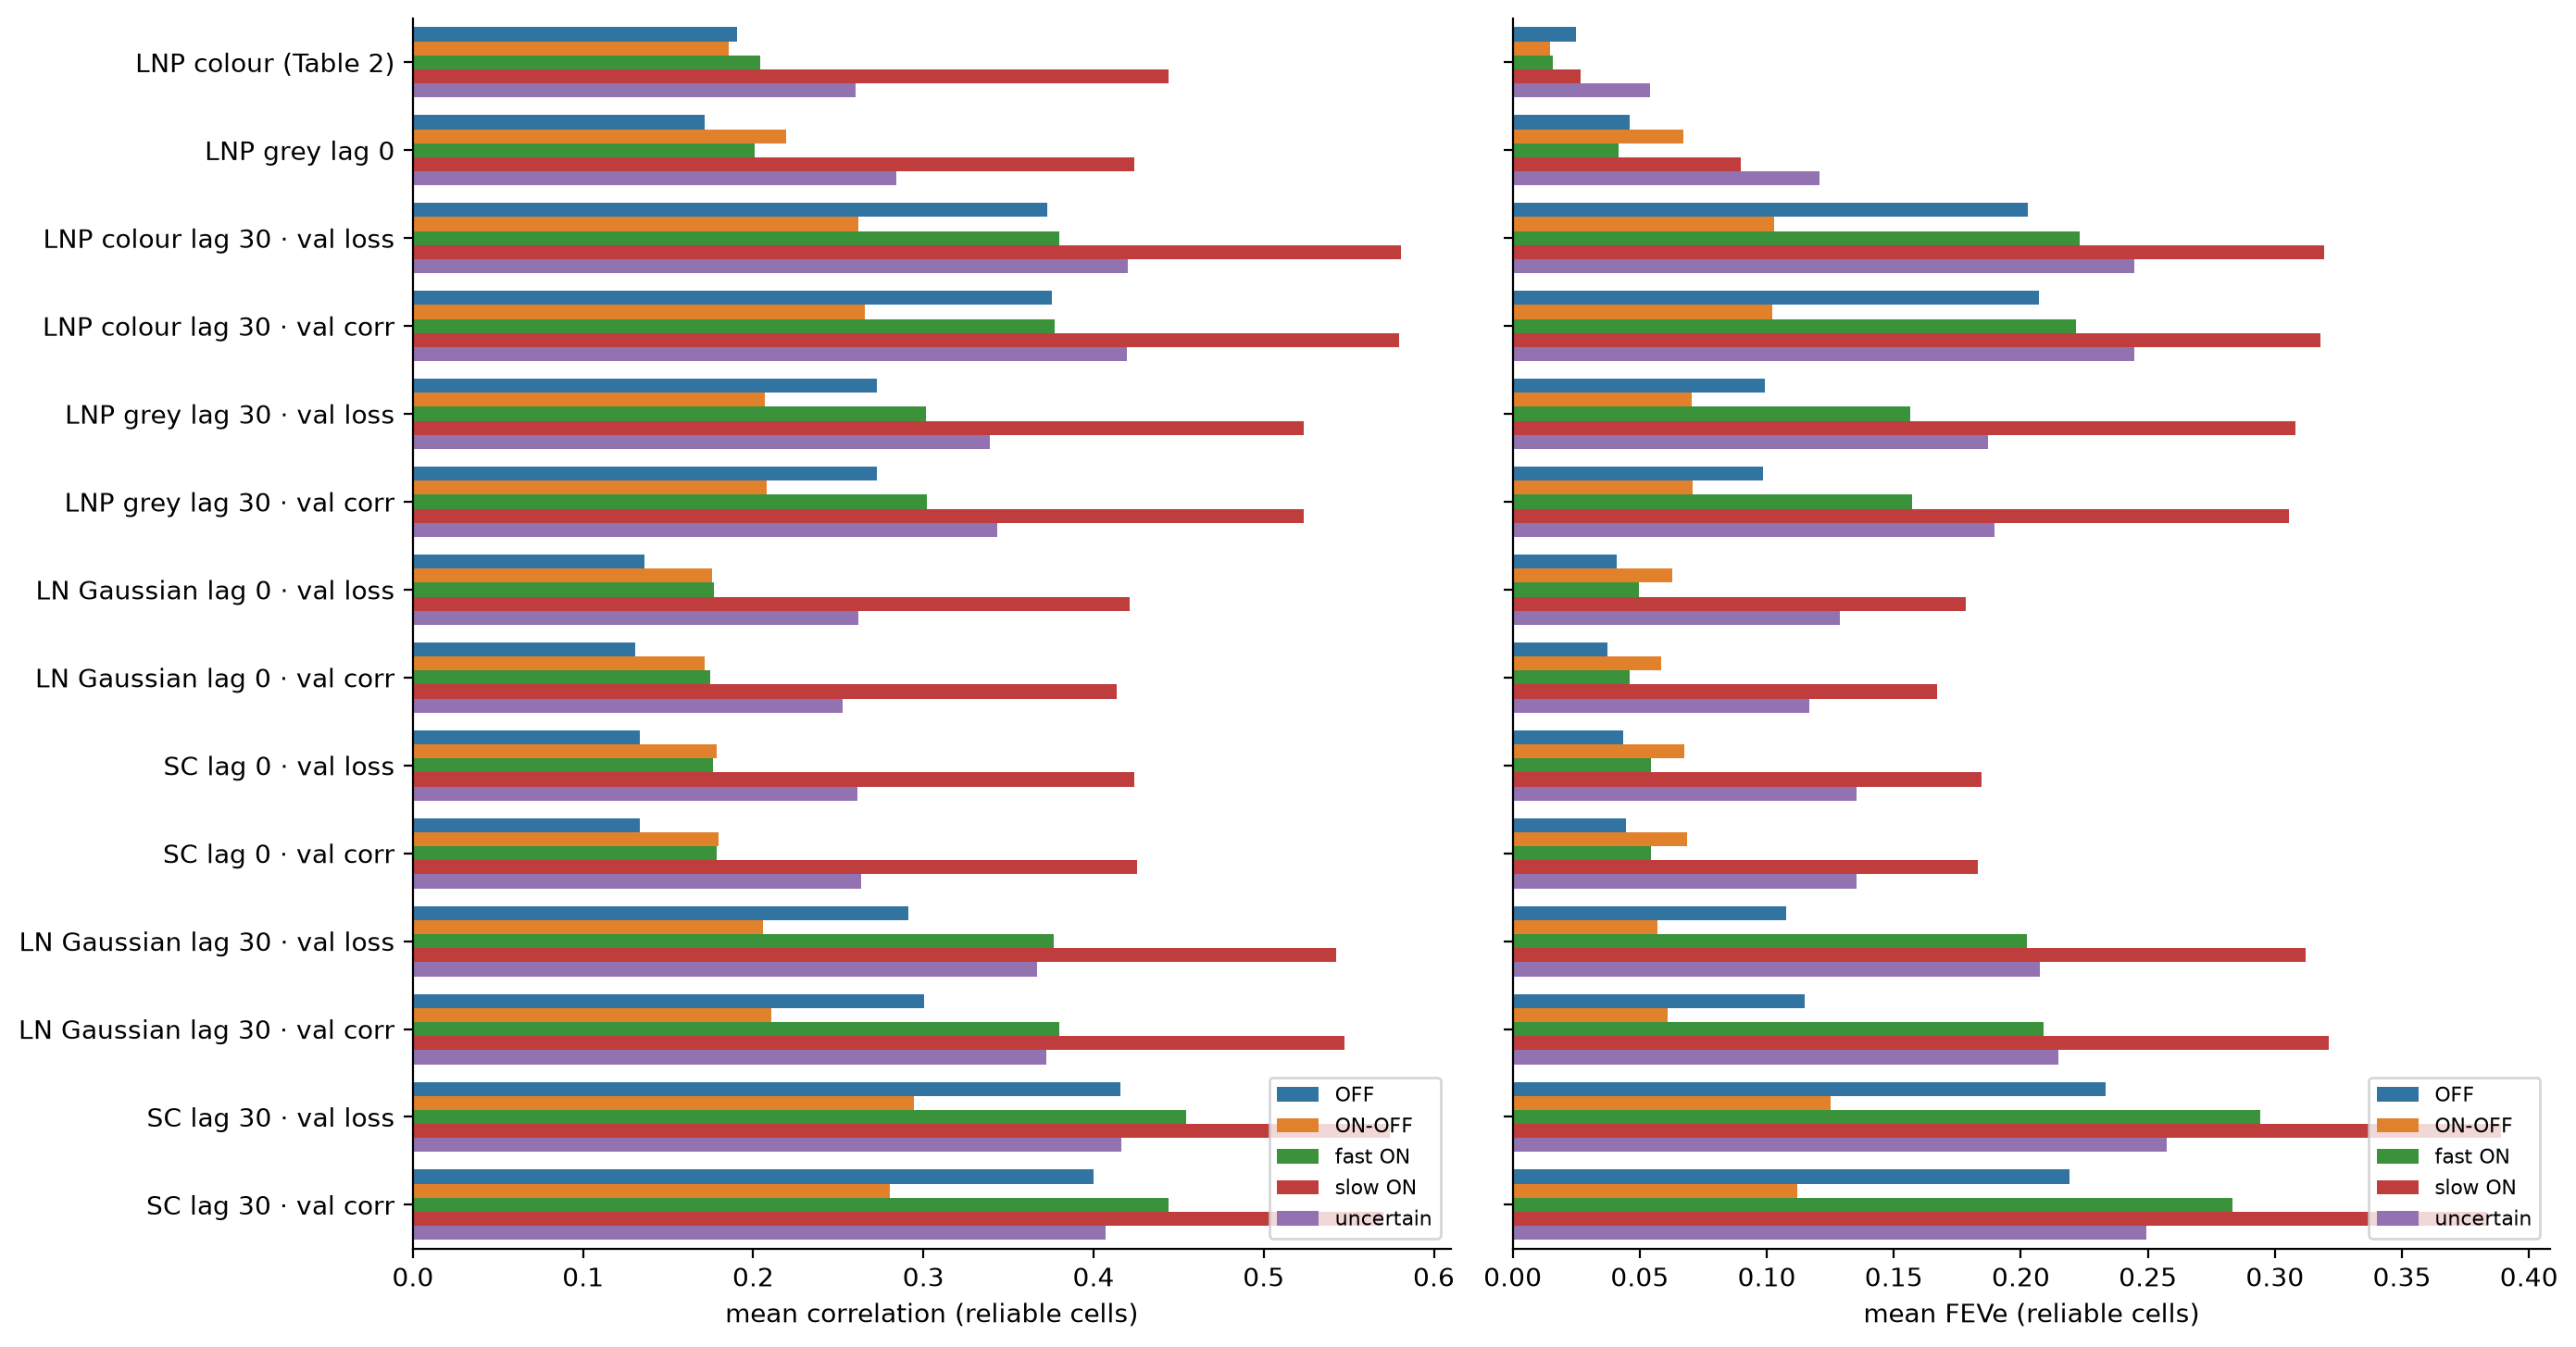

In [9]:
fig, axes = plt.subplots(ncols=2, figsize=(14, 0.42 * len(models) + 1.5), sharey=True)
for ax, value in zip(axes, ["correlation", "feve"]):
    sns.barplot(
        data=reliable, y="model", x=value, hue="group_class", ax=ax, errorbar=None, order=list(models), orient="h"
    )
    ax.set(xlabel="mean " + ("correlation" if value == "correlation" else "FEVe") + " (reliable cells)", ylabel="")
    ax.legend(title="", fontsize=8, loc="lower right")
sns.despine(fig=fig)
fig.tight_layout()

Cell-by-cell FEVe (reliable cells, models selected on validation loss) for the comparisons that isolate one ingredient
at a time: the contrast term (SC vs LN with the same filters) at lag 0 and lag 30, the lag, the Gaussian vs a free
spatial filter, and the colour LNP with and without its temporal kernels.

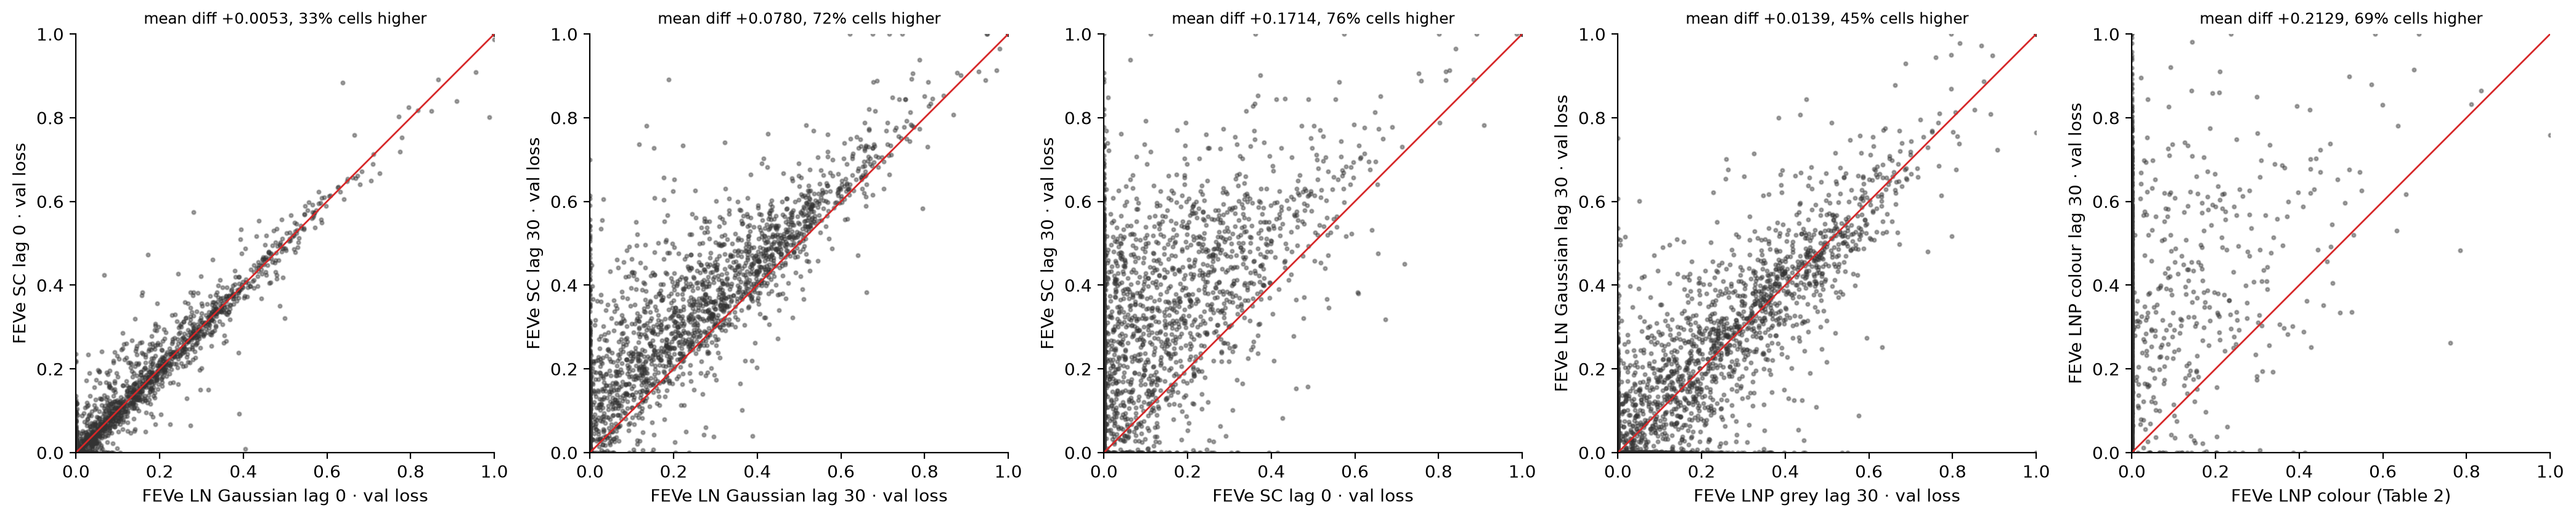

In [10]:
FEVE_PAIRS = [
    ("LN Gaussian lag 0 · val loss", "SC lag 0 · val loss"),
    ("LN Gaussian lag 30 · val loss", "SC lag 30 · val loss"),
    ("SC lag 0 · val loss", "SC lag 30 · val loss"),
    ("LNP grey lag 30 · val loss", "LN Gaussian lag 30 · val loss"),
    ("LNP colour (Table 2)", "LNP colour lag 30 · val loss"),
]
FEVE_PAIRS = [(a, b) for a, b in FEVE_PAIRS if a in models and b in models]
feve_wide = reliable.pivot_table(index=["session", "neuron"], columns="model", values="feve")

fig, axes = plt.subplots(ncols=max(len(FEVE_PAIRS), 1), figsize=(4.2 * max(len(FEVE_PAIRS), 1), 4.2), squeeze=False)
for ax, (a, b) in zip(axes[0], FEVE_PAIRS):
    ax.scatter(feve_wide[a], feve_wide[b], s=4, alpha=0.4, color="0.2", rasterized=True)
    ax.plot([0, 1], [0, 1], color="tab:red", lw=1)
    better = (feve_wide[b] > feve_wide[a]).mean()
    ax.set(xlabel=f"FEVe {a}", ylabel=f"FEVe {b}", xlim=(0, 1), ylim=(0, 1), aspect="equal")
    ax.set_title(f"mean diff {(feve_wide[b] - feve_wide[a]).mean():+.4f}, {better:.0%} cells higher", fontsize=9)
sns.despine(fig=fig)
fig.tight_layout()

# Selection criterion: validation loss vs validation correlation

Every trained model under both criteria. Selecting on validation correlation optimises the validation version of the
metric reported here, so it is expected to raise test correlation somewhat; the question is by how much, and whether
FEVe and calibration (which correlation ignores) follow.

First, from the training logs (validation metrics only): how long each run trained, the epoch its checkpoint comes
from, how often the learning rate was reduced, and both validation metrics at that epoch and at their best. The
validation Poisson loss is a sum over neurons for the LNPs and a mean for the LN and SC models, so it only compares
within a model.

In [11]:
def training_log(run_dir: Path) -> tuple[pd.DataFrame, int]:
    """Validation metrics per epoch, and the number of learning-rate reductions, from a run's csv log."""
    log = pd.read_csv(run_dir / "csv" / "metrics.csv")
    validation = log.dropna(subset=["val_evaluation_loss"]).groupby("epoch")[["val_evaluation_loss", "val_loss"]].last()
    validation.index = validation.index.astype(int)
    lr_column = next(c for c in log.columns if c.startswith("lr-") and not c.endswith(("-momentum", "-weight_decay")))
    lr = log.dropna(subset=[lr_column]).sort_values("step")[lr_column]
    return validation.rename(columns={"val_evaluation_loss": "val corr", "val_loss": "val loss"}), int((lr.diff() < 0).sum())


training_logs, training_rows = {}, []
for label in models:
    location = MODELS[label][1]
    if not (isinstance(location, Path) and (location / "csv" / "metrics.csv").exists()):
        continue
    log, n_reductions = training_log(location)
    selected = int(re.search(r"epoch=(\d+)", Path(resolve_checkpoint(location)).name).group(1))
    training_logs[label] = (log, selected)
    training_rows.append(
        {
            "model": label,
            "epochs run": len(log),
            "selected epoch": selected,
            "LR reductions": n_reductions,
            "val corr (selected)": log.loc[selected, "val corr"],
            "best val corr": log["val corr"].max(),
            "val loss (selected)": log.loc[selected, "val loss"],
            "best val loss": log["val loss"].min(),
        }
    )
training_table = pd.DataFrame(training_rows).set_index("model")
training_table.style.format(
    {
        "val corr (selected)": "{:.4f}",
        "best val corr": "{:.4f}",
        "val loss (selected)": "{:.6g}",
        "best val loss": "{:.6g}",
    }
)

,epochs run,selected epoch,LR reductions,val corr (selected),best val corr,val loss (selected),best val loss
model,,,,,,,
LNP colour lag 30 · val loss,109,98,3,0.1604,0.1613,364.125,364.125
LNP colour lag 30 · val corr,145,136,3,0.1626,0.1626,364.398,364.346
LNP grey lag 30 · val loss,118,107,3,0.1393,0.1394,368.388,368.388
LNP grey lag 30 · val corr,120,119,3,0.1403,0.1403,368.448,368.407
LN Gaussian lag 0 · val loss,230,219,3,0.1192,0.1193,0.00445953,0.00445953
LN Gaussian lag 0 · val corr,137,128,3,0.1107,0.1107,0.00446854,0.00446846
SC lag 0 · val loss,231,220,3,0.1175,0.1175,0.00445183,0.00445183
SC lag 0 · val corr,215,211,3,0.1188,0.1188,0.0044506,0.00445059
LN Gaussian lag 30 · val loss,84,73,3,0.1830,0.1834,0.00440507,0.00440507


Validation correlation (top) and Poisson loss (bottom) over training, for the run selected on validation loss (dark)
and on validation correlation (light); the dot marks the epoch each run's checkpoint comes from. Until the first
learning-rate reduction the two runs are identical, so the curves only part where the schedules or the stopping
differ.

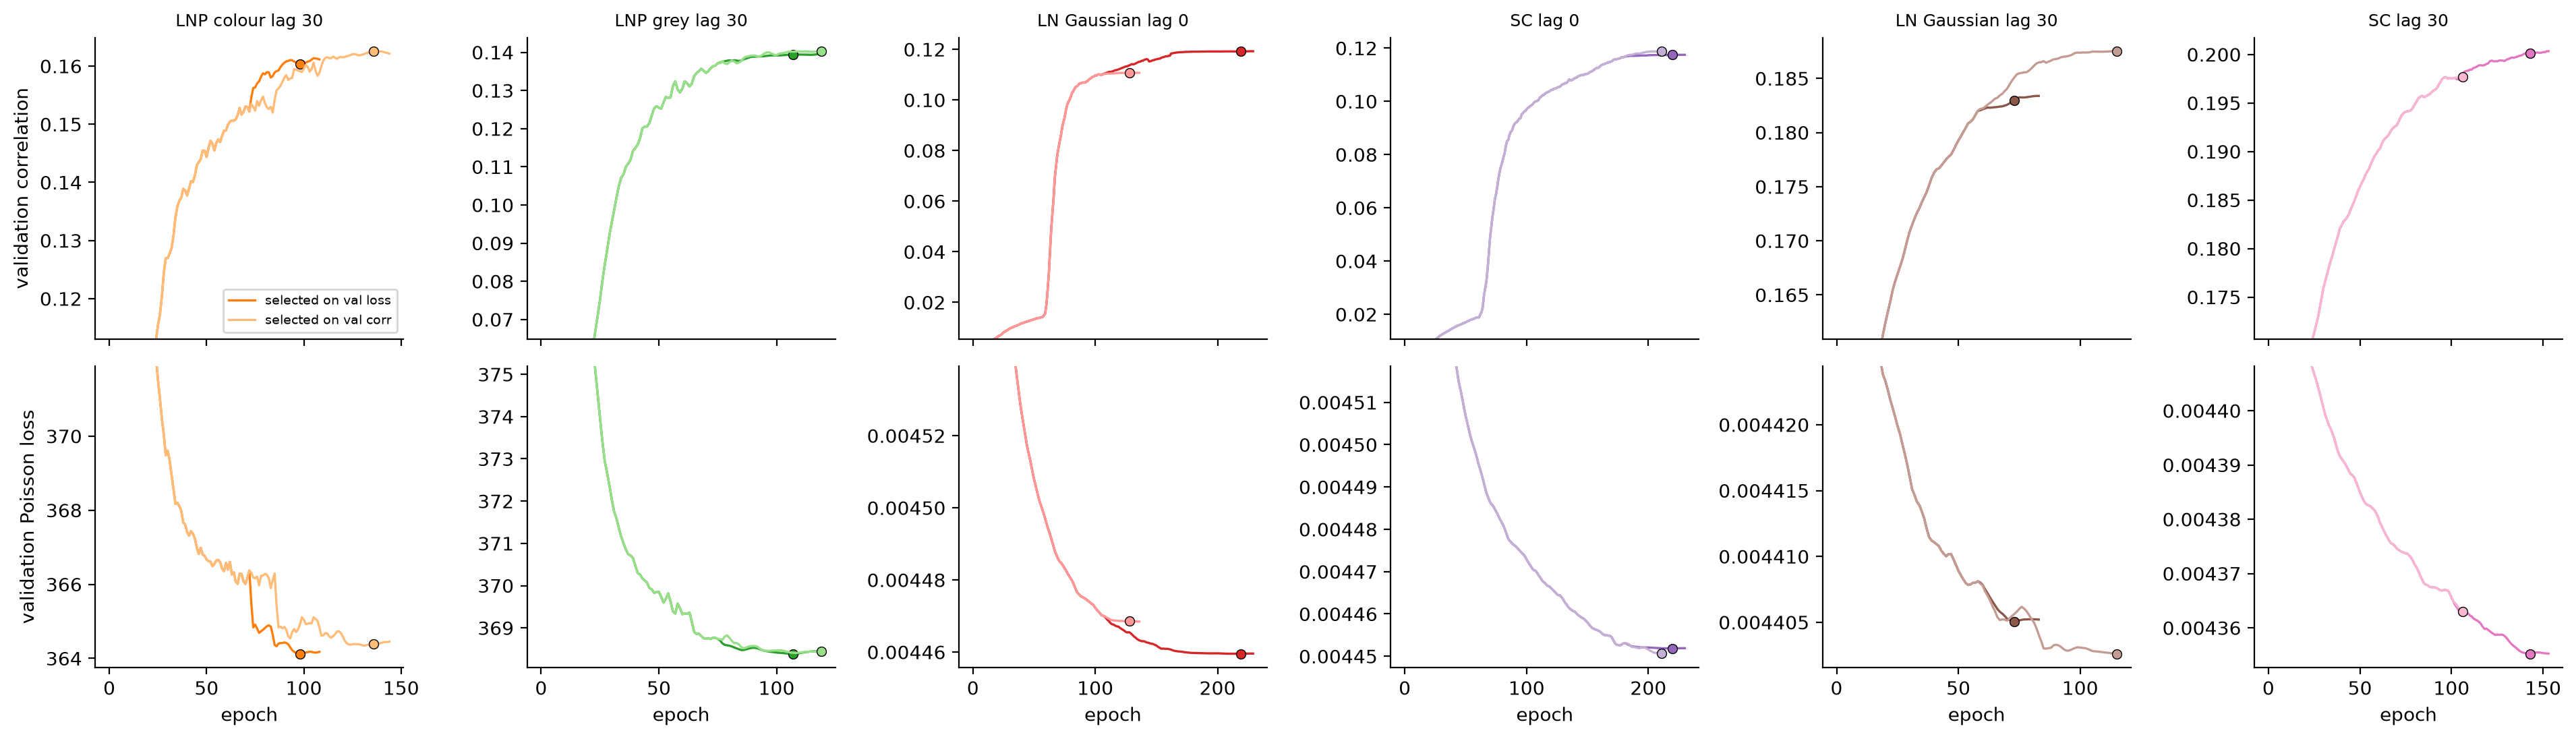

In [12]:
curve_models = [n for n in TRAINED_MODELS if any(f"{n} · {c}" in training_logs for c in CRITERIA)]
fig, axes = plt.subplots(
    nrows=2, ncols=len(curve_models), figsize=(3.2 * len(curve_models), 5.6), sharex="col", squeeze=False
)
for column, name in enumerate(curve_models):
    labels = [f"{name} · {c}" for c in CRITERIA if f"{name} · {c}" in training_logs]
    for row, value in enumerate(["val corr", "val loss"]):
        ax = axes[row, column]
        for label in labels:
            log, selected = training_logs[label]
            ax.plot(log.index, log[value], color=palette[label], lw=1.2, label=f"selected on {label.split(' · ')[1]}")
            ax.plot(selected, log.loc[selected, value], "o", color=palette[label], ms=5, mec="k", mew=0.5)
        # Zoom in on the end of training: the first epochs would set the scale otherwise
        values = np.concatenate([training_logs[label][0][value].to_numpy() for label in labels])
        if value == "val corr":
            low, high = np.percentile(values, 20), values.max()
        else:
            low, high = values.min(), np.percentile(values, 80)
        ax.set_ylim(low - 0.05 * (high - low), high + 0.05 * (high - low))
    axes[0, column].set_title(name, fontsize=9)
    axes[1, column].set_xlabel("epoch")
axes[0, 0].set_ylabel("validation correlation")
axes[1, 0].set_ylabel("validation Poisson loss")
axes[0, 0].legend(fontsize=7)
sns.despine(fig=fig)
fig.tight_layout()

The Table 2 numbers of each trained model under both criteria (test set, reliable cells), and the paired difference
val corr - val loss over the same cells with 95% confidence intervals from resampling sessions, as above. `cells
higher` and `cells lower` are the fractions of reliable cells whose FEVe is higher or lower under val corr; the rest
tie, mostly at FEVe = 0.

In [13]:
criterion_pairs = [
    (name, f"{name} · val loss", f"{name} · val corr")
    for name in TRAINED_MODELS
    if f"{name} · val loss" in models and f"{name} · val corr" in models
]
side_by_side = pd.concat(
    {
        criterion: table2.loc[[f"{name} · {criterion}" for name, *_ in criterion_pairs], numeric].set_axis(
            [name for name, *_ in criterion_pairs]
        )
        for criterion in CRITERIA
    },
    axis=1,
).swaplevel(axis=1)[[(value, criterion) for value in numeric for criterion in CRITERIA]]
display(side_by_side.round(3))

criterion_rows = []
for name, a, b in criterion_pairs:
    row = {"model": name}
    for value, column in [("correlation", "Δ Avg"), ("feve", "Δ FEVe")]:
        mean, low, high = paired_difference(a, b, value)
        row[column] = f"{mean:+.3f} [{low:+.3f}, {high:+.3f}]"
    row["cells higher"] = (feve_wide[b] > feve_wide[a]).mean()
    row["cells lower"] = (feve_wide[b] < feve_wide[a]).mean()
    criterion_rows.append(row)
pd.DataFrame(criterion_rows, columns=["model", "Δ Avg", "Δ FEVe", "cells higher", "cells lower"]).set_index("model").round(3)

Avg              FEVe          FEVe = 0           \
                   val loss val corr val loss val corr val loss val corr   
LNP colour lag 30     0.440    0.440    0.242    0.241    0.291    0.297   
LNP grey lag 30       0.369    0.370    0.196    0.196    0.283    0.291   
LN Gaussian lag 0     0.274    0.267    0.112    0.103    0.429    0.397   
SC lag 0              0.274    0.276    0.117    0.117    0.412    0.419   
LN Gaussian lag 30    0.398    0.403    0.210    0.218    0.286    0.275   
SC lag 30             0.460    0.451    0.288    0.279    0.167    0.185   

                   median calibration           
                             val loss val corr  
LNP colour lag 30               1.037    1.034  
LNP grey lag 30                 1.044    1.045  
LN Gaussian lag 0               1.055    1.046  
SC lag 0                        1.045    1.046  
LN Gaussian lag 30              1.051    1.049  
SC lag 30                       1.005    1.011

,Δ Avg,Δ FEVe,cells higher,cells lower
model,,,,
LNP colour lag 30,"-0.000 [-0.002, +0.002]","-0.001 [-0.003, +0.002]",0.375,0.358
LNP grey lag 30,"+0.001 [+0.000, +0.003]","-0.000 [-0.002, +0.001]",0.366,0.359
LN Gaussian lag 0,"-0.006 [-0.008, -0.005]","-0.008 [-0.011, -0.006]",0.237,0.387
SC lag 0,"+0.001 [+0.001, +0.002]","-0.000 [-0.001, +0.001]",0.313,0.282
LN Gaussian lag 30,"+0.005 [+0.004, +0.006]","+0.007 [+0.006, +0.009]",0.471,0.262
SC lag 30,"-0.009 [-0.010, -0.008]","-0.009 [-0.011, -0.007]",0.307,0.528


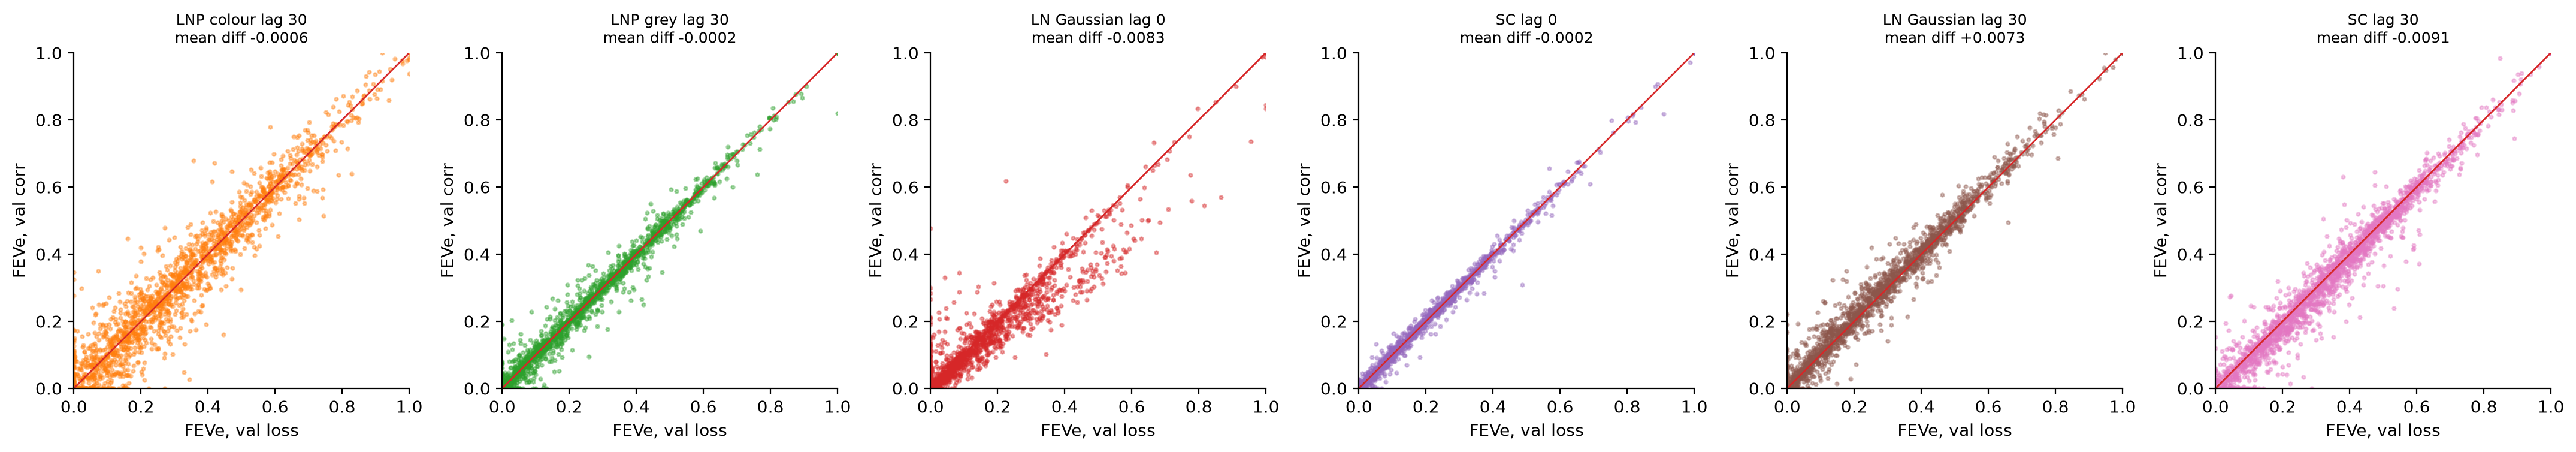

In [14]:
fig, axes = plt.subplots(
    ncols=max(len(criterion_pairs), 1), figsize=(3.6 * max(len(criterion_pairs), 1), 3.8), squeeze=False
)
for ax, (name, a, b) in zip(axes[0], criterion_pairs):
    ax.scatter(feve_wide[a], feve_wide[b], s=4, alpha=0.4, color=palette[a], rasterized=True)
    ax.plot([0, 1], [0, 1], color="tab:red", lw=1)
    ax.set(xlabel="FEVe, val loss", ylabel="FEVe, val corr", xlim=(0, 1), ylim=(0, 1), aspect="equal")
    ax.set_title(f"{name}\nmean diff {(feve_wide[b] - feve_wide[a]).mean():+.4f}", fontsize=9)
sns.despine(fig=fig)
fig.tight_layout()

**What the criterion changes.** The ranking of the models is the same under both criteria. For the two LNPs the
criterion makes no difference on the test set (Δ Avg -0.000 and +0.001). For the LN and SC models the differences
are small but outside their confidence intervals, and they go both ways: selecting on validation correlation is better
for LN lag 30 (+0.005), worse for SC lag 30 (-0.009) and LN lag 0 (-0.006), and neutral for SC lag 0 (+0.001).
Median calibration moves by at most 0.01. So selecting on the reported metric does not systematically raise it here.
The differences arise because the training paths part once the learning-rate schedules do (SC lag 30, for example,
reduced its learning rate once under val corr and three times under val loss). Every run is a single seed, and how
large run-to-run differences are was not measured.

# Filters

The spatial and temporal filter of a few cells. For the lag-30 LNP these are the two factors the model learns; for the
lag-0 LNP, the learned spatial filter and a single-frame temporal filter. Spatial Contrast filters are the masked
Gaussians and normalised temporal filters the model uses. All filters are shown the way the Spatial Contrast model holds
them: the spatial filter's strongest pixel is positive, so the ON/OFF polarity is in the temporal filter, which has unit
norm. For the LN and SC models, the starting Gaussian (the same for every cell) is outlined in dashes and the random
starting temporal filter drawn dashed.

The large weight on the current frame (0 ms) of the earlier, delta-initialised LNP is discussed in
[Why the temporal filters peak at the current frame](#Why-the-temporal-filters-peak-at-the-current-frame).

Example cells: the reliable cell of each functional group that the reference model predicts best (by correlation).

In [15]:
def lnp_filter_factors(readout, neuron: int) -> tuple[np.ndarray, np.ndarray]:
    """Spatial (H, W) and unit-norm temporal (T,) factor of one LNP neuron's filter, with the spatial filter's strongest
    pixel positive, so that the ON/OFF polarity sits in the temporal filter as in the Spatial Contrast model."""
    with torch.no_grad():
        if isinstance(readout, SeparableLNPReadout):  # the factors the model learns
            spatial = readout.spatial_kernel.weight[neuron, 0, 0].cpu().numpy()
            temporal = readout.temporal_kernel.weight[neuron, 0, :, 0, 0].cpu().numpy()
        else:  # best rank-1 approximation of the full filter, exact for a single frame
            sta = readout.spatiotemporal_filters()[neuron, 0].cpu().numpy()  # (T, H, W)
            u, s, vt = np.linalg.svd(sta.reshape(len(sta), -1), full_matrices=False)
            temporal, spatial = u[:, 0], s[0] * vt[0].reshape(sta.shape[1:])
    sign = np.sign(spatial.flat[np.abs(spatial).argmax()]) or 1.0
    norm = np.linalg.norm(temporal) or 1.0
    return sign * norm * spatial, sign * temporal / norm  # their product is the model's filter


def neuron_filters(model, session: str, neuron: int) -> dict[str, np.ndarray]:
    """Spatial filter (H, W) and temporal filter (T,) of one neuron; index -1 of the temporal filter is the current frame."""
    readout = model.readout[session]
    if isinstance(readout, SpatialContrastReadout):
        with torch.no_grad():
            spatial, temporal, _ = readout._filters()
        filters = {"spatial": spatial[neuron].cpu().numpy(), "temporal": temporal[neuron].cpu().numpy()}
        if isinstance(readout, LearnableFilterSpatialContrastReadout):
            filters["initial_spatial"] = readout.spatial_filters[neuron].cpu().numpy()
            filters["initial_temporal"] = readout.temporal_filters[neuron].cpu().numpy()
        return filters
    spatial, temporal = lnp_filter_factors(readout, neuron)
    return {"spatial": spatial, "temporal": temporal}


reference = reliable[reliable["model"] == (REFERENCE_MODEL if REFERENCE_MODEL in models else next(iter(models)))]
example_cells = [
    (row.session, row.neuron)
    for _, row in reference.sort_values("correlation", ascending=False)
    .groupby("group_class", observed=True)
    .head(1)
    .iterrows()
]
cell_info = metrics.drop_duplicates(["session", "neuron"]).set_index(["session", "neuron"])
example_cells

[('session_3_ventral2_20201022', 11),
 ('session_2_ventral2_20210929', 39),
 ('session_1_ventral2_20200302', 7),
 ('session_2_ventral1_20200528', 1),
 ('session_2_ventral1_20201021', 18)]

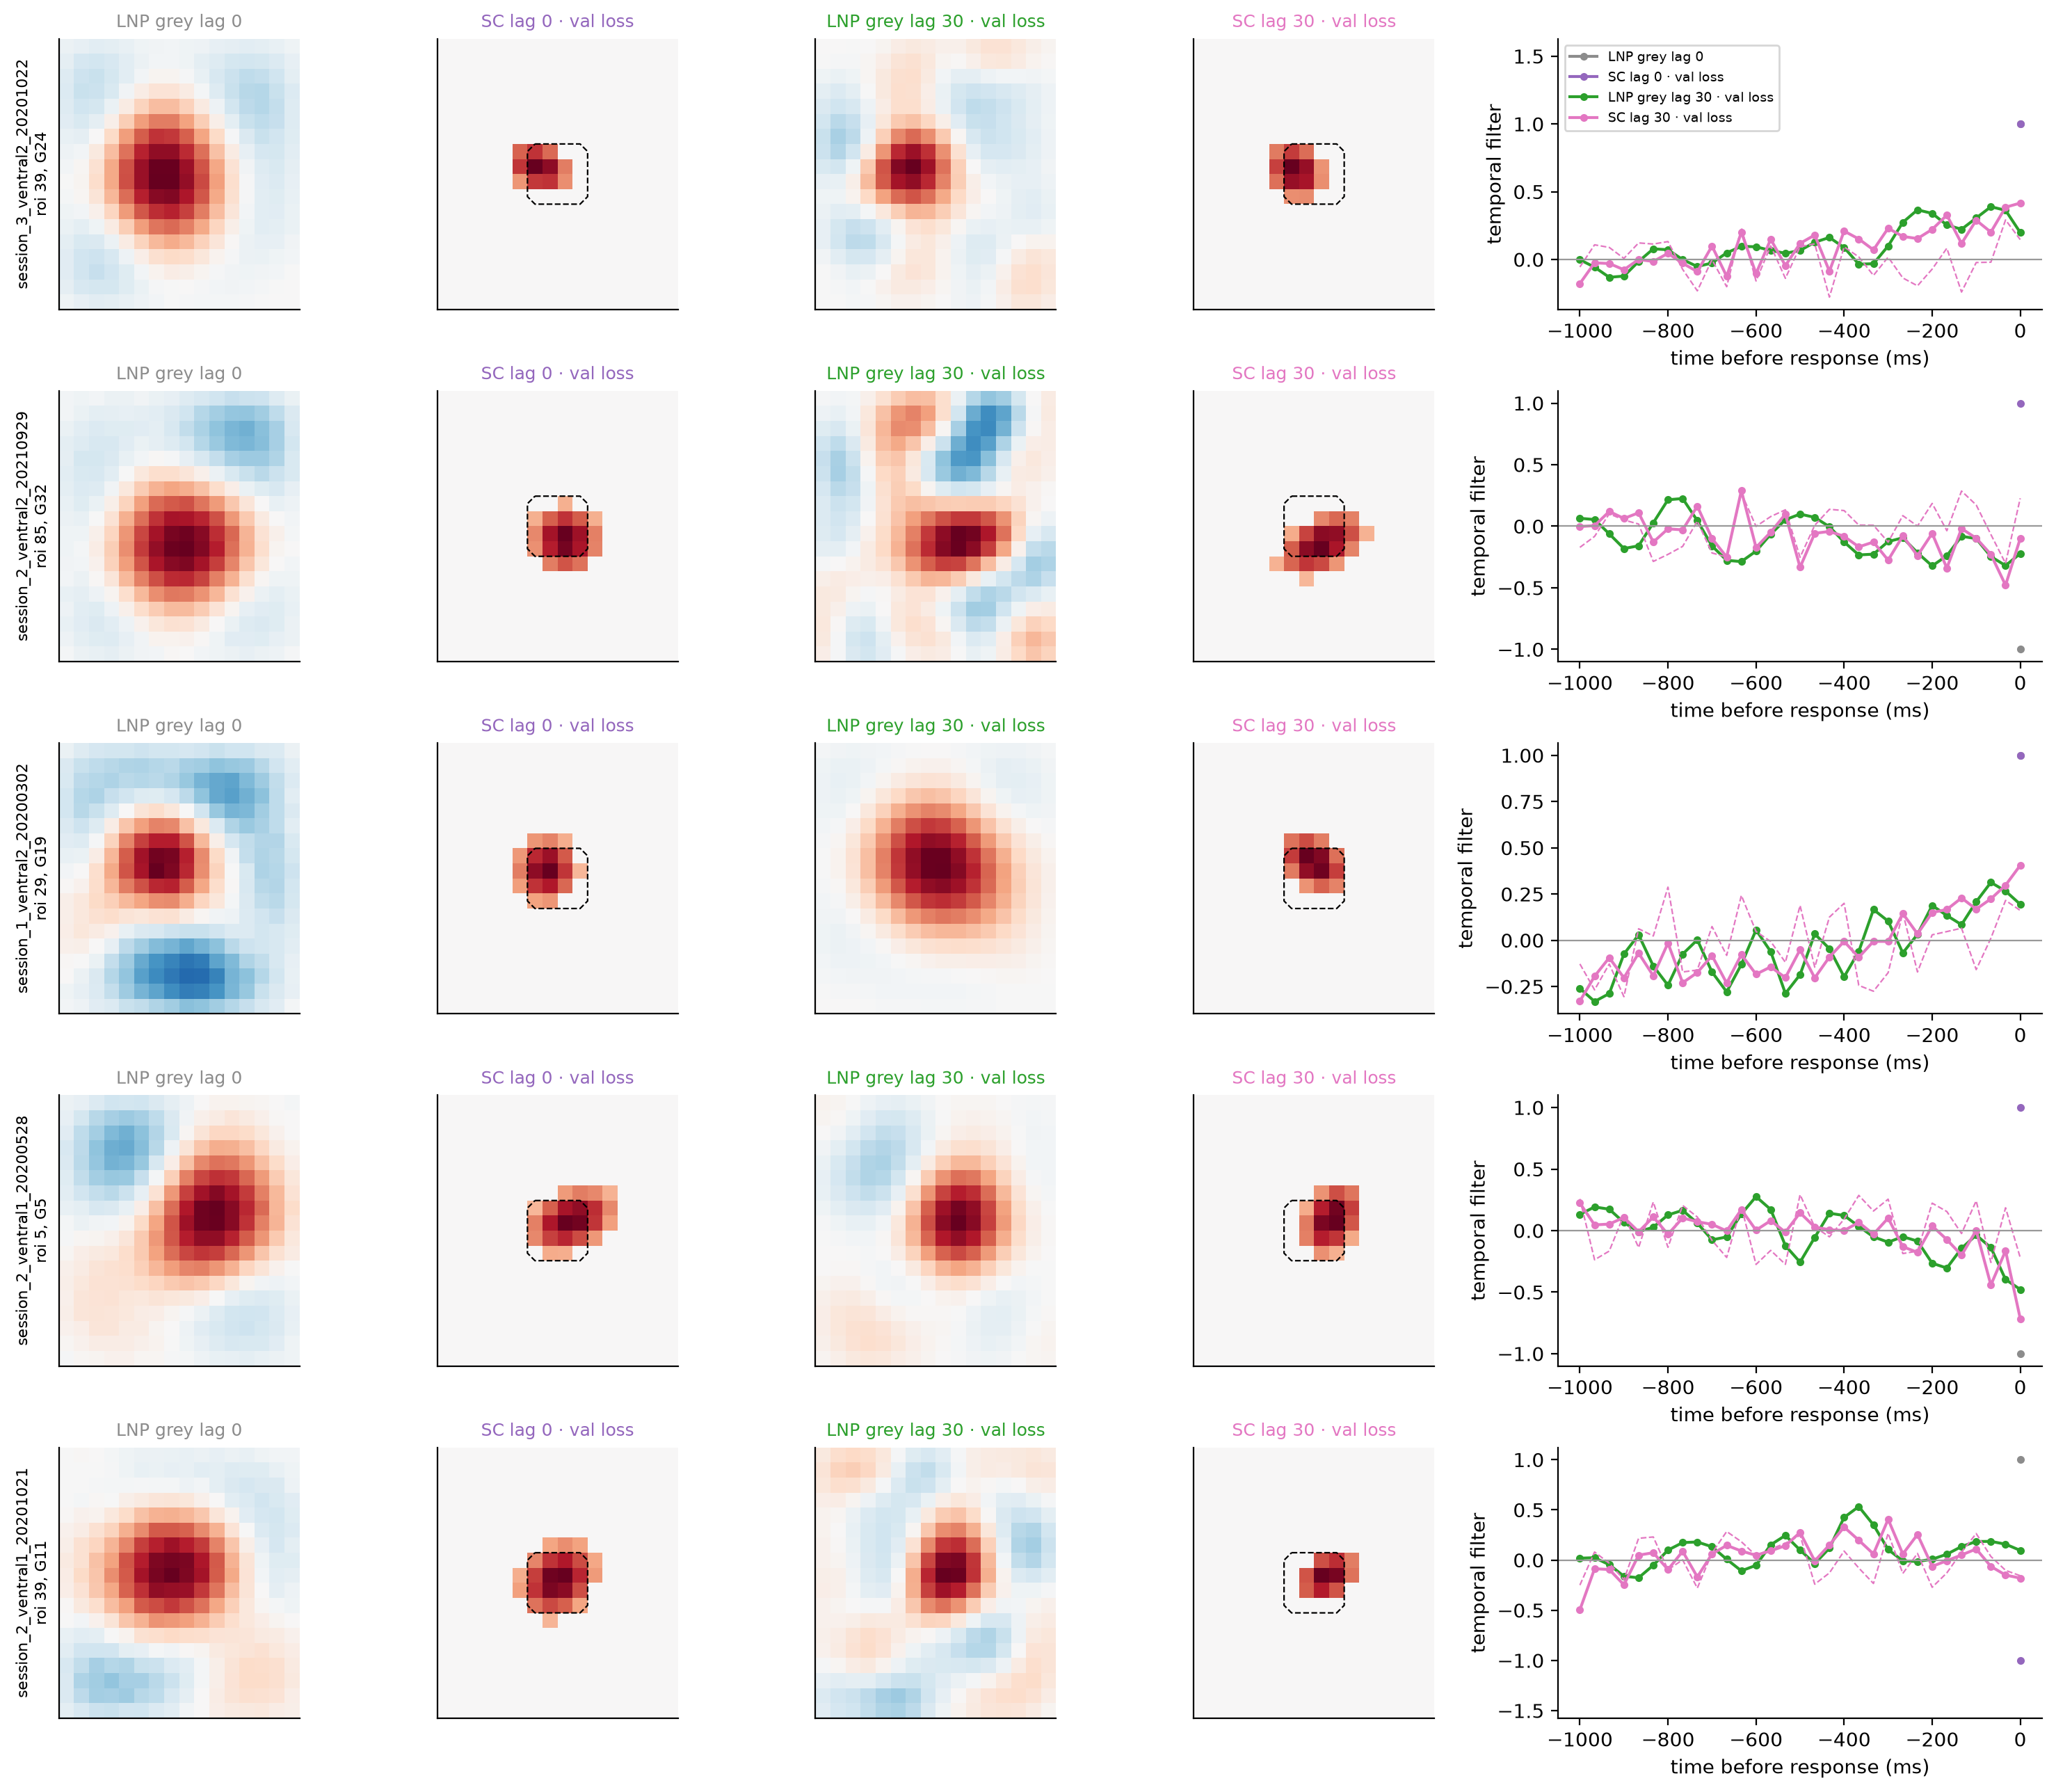

In [16]:
def lags_ms(n_frames: int) -> np.ndarray:
    return np.arange(-n_frames + 1, 1) * 1000 / FRAME_RATE_HZ


fig, axes = plt.subplots(
    nrows=len(example_cells),
    ncols=len(FILTER_MODELS) + 1,
    figsize=(2.6 * len(FILTER_MODELS) + 4.5, 2.6 * len(example_cells)),
    gridspec_kw={"width_ratios": [1] * len(FILTER_MODELS) + [1.8]},
    squeeze=False,
)
for row_axes, (session, neuron) in zip(axes, example_cells):
    info = cell_info.loc[(session, neuron)]
    ax_time = row_axes[-1]
    for ax, label in zip(row_axes[:-1], FILTER_MODELS):
        filters = neuron_filters(models[label], session, neuron)
        spatial = filters["spatial"]
        limit = np.abs(spatial).max() or 1.0
        ax.imshow(spatial, cmap="RdBu_r", vmin=-limit, vmax=limit, interpolation="none")
        if "initial_spatial" in filters:
            ax.contour(filters["initial_spatial"] > 0, levels=[0.5], colors="k", linestyles="--", linewidths=0.8)
        ax.set_xticks([])
        ax.set_yticks([])
        ax.set_title(label, fontsize=9, color=palette[label])

        temporal = filters["temporal"]
        ax_time.plot(lags_ms(len(temporal)), temporal, marker="o", ms=3, color=palette[label], label=label)
        if "initial_temporal" in filters:
            initial = filters["initial_temporal"]
            ax_time.plot(lags_ms(len(initial)), initial, ls="--", color=palette[label], lw=0.8)
    row_axes[0].set_ylabel(f"{session}\nroi {info.roi_id}, G{info.group}", fontsize=8)
    ax_time.axhline(0, color="0.6", lw=0.8)
    ax_time.set(xlabel="time before response (ms)", ylabel="temporal filter")
axes[0, -1].legend(fontsize=7)
sns.despine(fig=fig)
fig.tight_layout()

## Colour LNP lag 30: green and UV

The same cells' filters in the colour lag-30 LNP, which has a spatial filter and a temporal kernel per channel, under
both selection criteria. Each channel is shown like the grey filters above: its temporal kernel has unit norm and its
spatial filter's strongest pixel is positive, so each channel's polarity is in its temporal kernel. Both channels of a
model share one colour scale. Below, the mean temporal kernel of each channel per functional group. With the temporal
smoothness of 1e3 the single-cell kernels are no longer white noise, but many still oscillate over a few frames;
the group means do not.

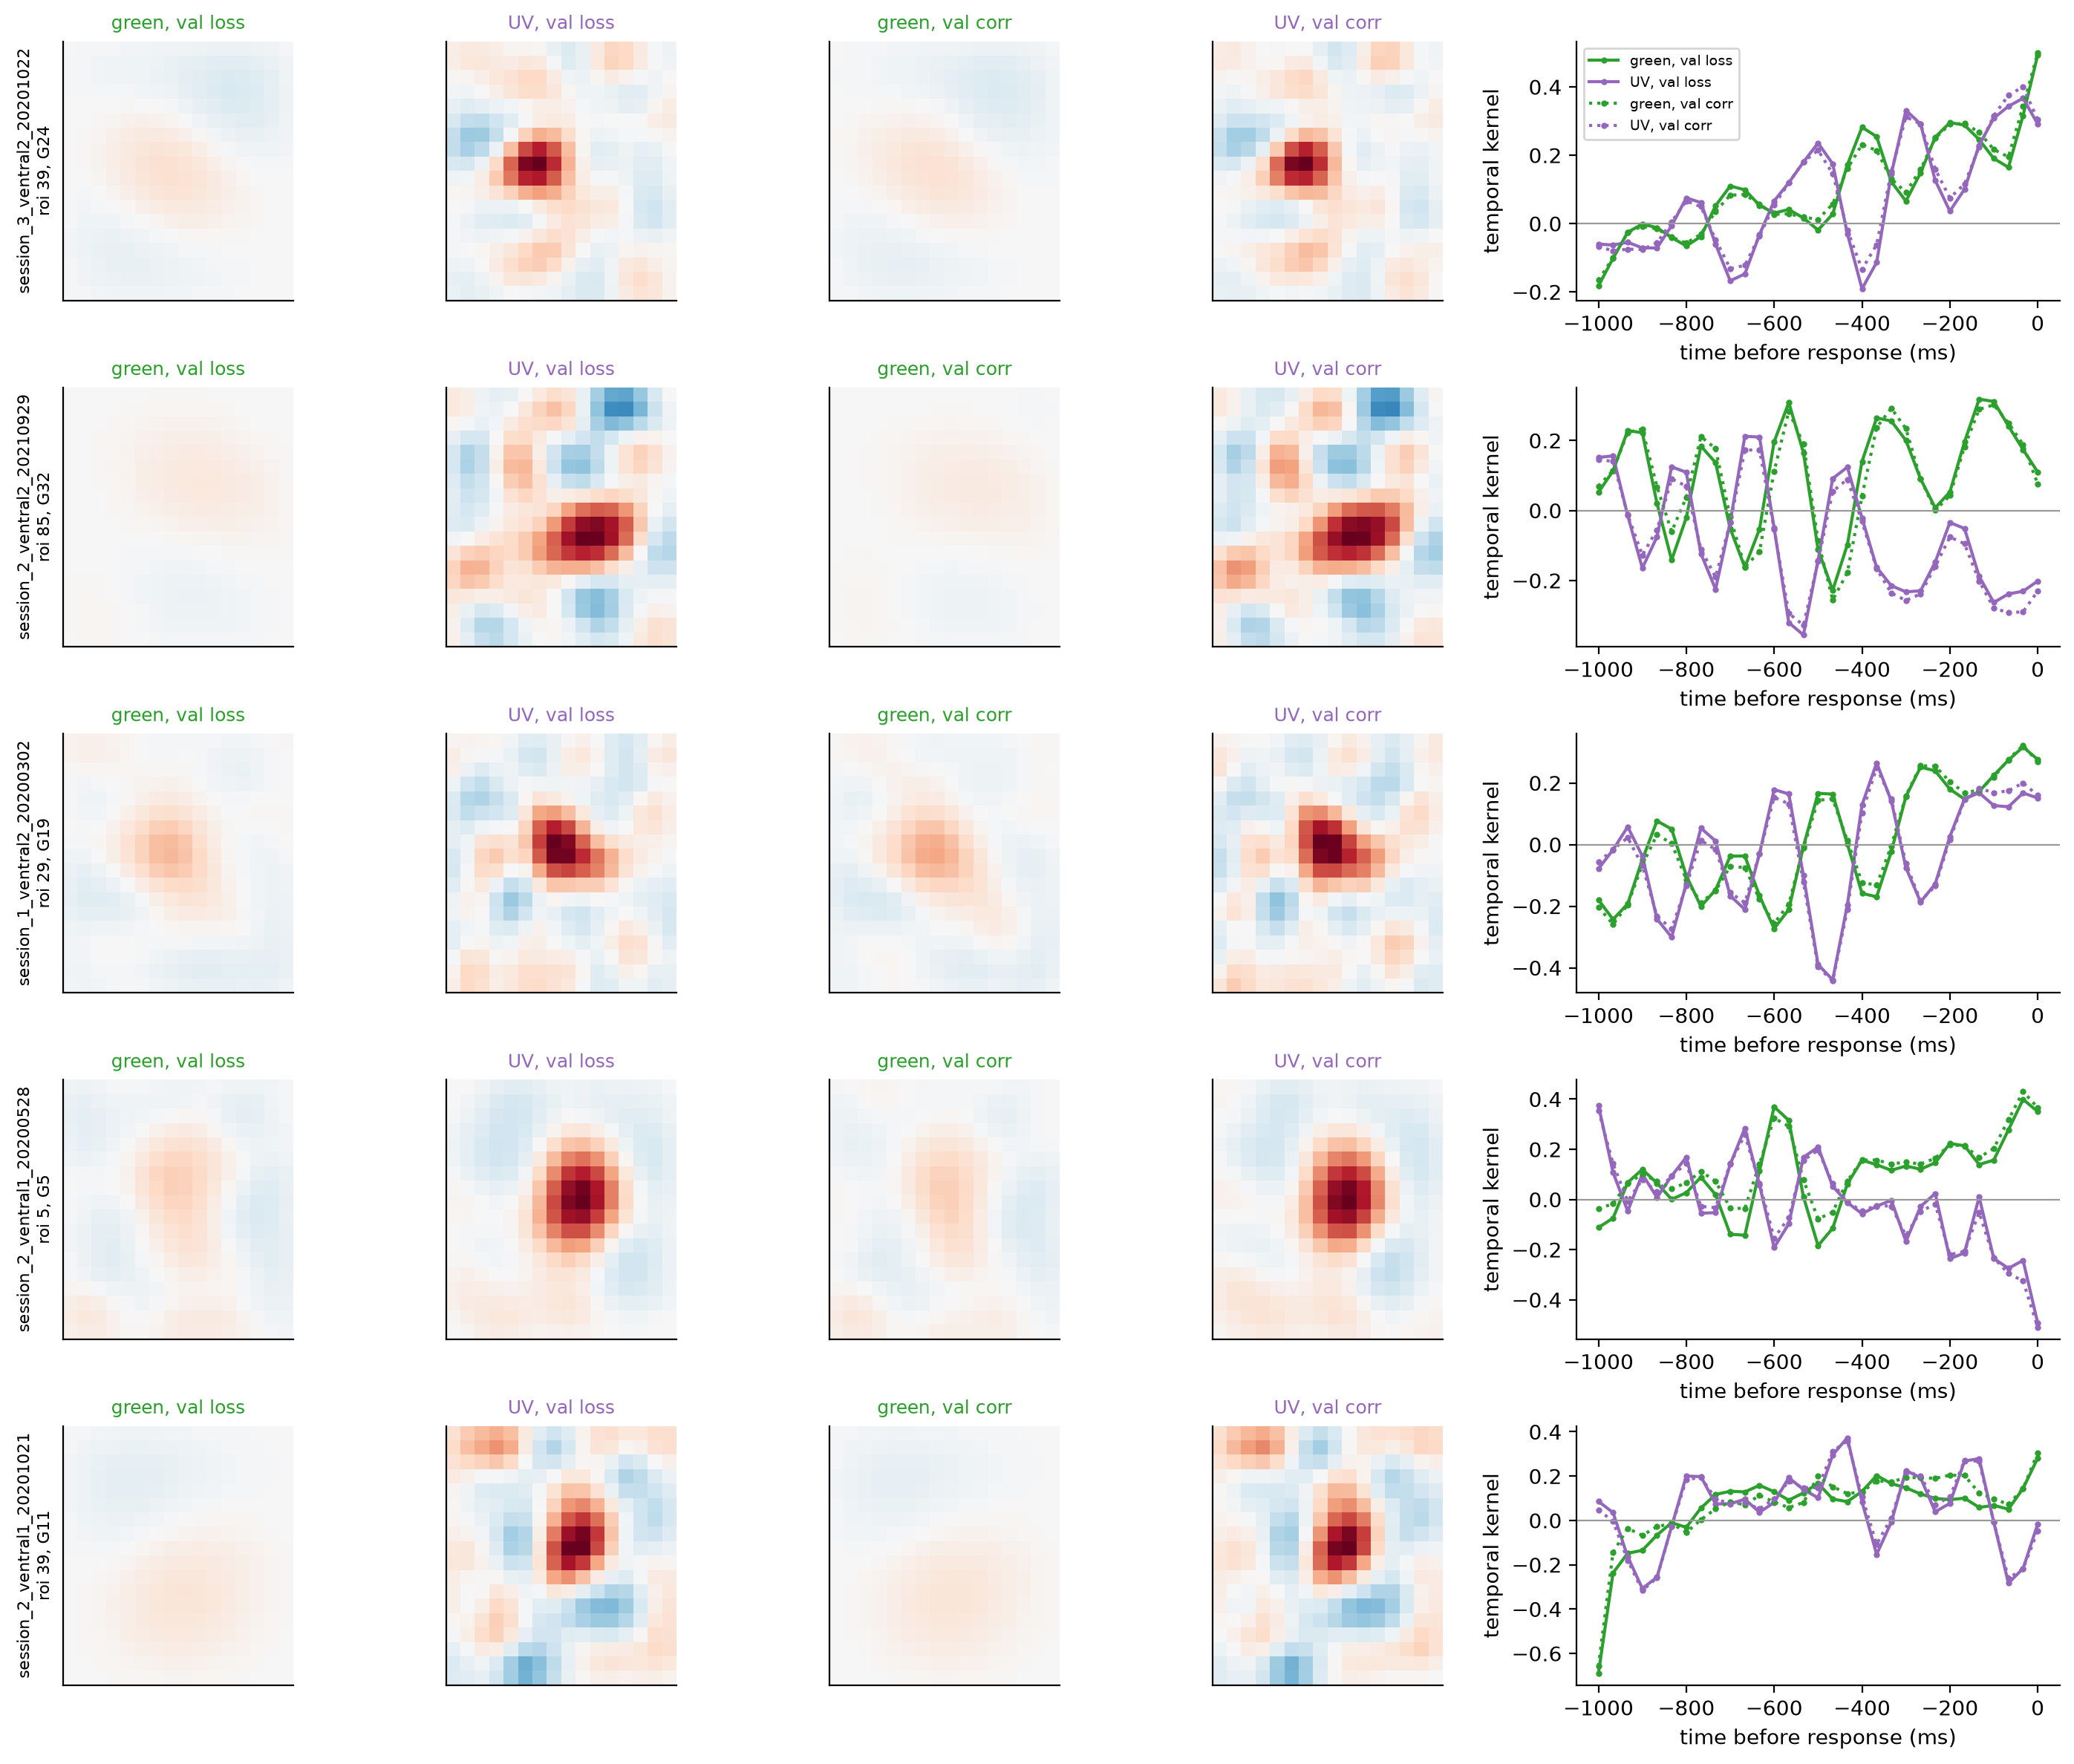

In [17]:
CHANNELS = {"green": "tab:green", "UV": "tab:purple"}
CRITERION_STYLES = {"val loss": "-", "val corr": ":"}


def colour_filter_factors(readout, neuron: int) -> tuple[np.ndarray, np.ndarray]:
    """Spatial (C, H, W) and unit-norm temporal (C, T) factors of one neuron of a separable LNP with a temporal kernel
    per channel, each channel's spatial filter with its strongest pixel positive; channel by channel, their product is
    the model's filter."""
    with torch.no_grad():
        spatial = readout.spatial_kernel.weight[neuron, :, 0].cpu().numpy()
        temporal = readout.temporal_kernels()[neuron].cpu().numpy()
    flat = spatial.reshape(len(spatial), -1)
    sign = np.sign(flat[np.arange(len(flat)), np.abs(flat).argmax(axis=1)])
    sign[sign == 0] = 1.0
    norm = np.linalg.norm(temporal, axis=1)
    norm[norm == 0] = 1.0
    return spatial * (sign * norm)[:, None, None], temporal * (sign / norm)[:, None]


if COLOUR_FILTER_MODELS:
    n_maps = len(COLOUR_FILTER_MODELS) * len(CHANNELS)
    fig, axes = plt.subplots(
        nrows=len(example_cells),
        ncols=n_maps + 1,
        figsize=(2.4 * n_maps + 4.5, 2.4 * len(example_cells)),
        gridspec_kw={"width_ratios": [1] * n_maps + [1.8]},
        squeeze=False,
    )
    for row_axes, (session, neuron) in zip(axes, example_cells):
        info = cell_info.loc[(session, neuron)]
        ax_time = row_axes[-1]
        map_axes = iter(row_axes[:-1])
        for label in COLOUR_FILTER_MODELS:
            criterion = label.split(" · ")[1]
            spatial, temporal = colour_filter_factors(models[label].readout[session], neuron)
            limit = np.abs(spatial).max() or 1.0
            for (channel, colour), channel_spatial, channel_temporal in zip(CHANNELS.items(), spatial, temporal):
                ax = next(map_axes)
                ax.imshow(channel_spatial, cmap="RdBu_r", vmin=-limit, vmax=limit, interpolation="none")
                ax.set_xticks([])
                ax.set_yticks([])
                ax.set_title(f"{channel}, {criterion}", fontsize=9, color=colour)
                ax_time.plot(
                    lags_ms(len(channel_temporal)),
                    channel_temporal,
                    ls=CRITERION_STYLES[criterion],
                    marker="o",
                    ms=2,
                    color=colour,
                    label=f"{channel}, {criterion}",
                )
        row_axes[0].set_ylabel(f"{session}\nroi {info.roi_id}, G{info.group}", fontsize=8)
        ax_time.axhline(0, color="0.6", lw=0.8)
        ax_time.set(xlabel="time before response (ms)", ylabel="temporal kernel")
    axes[0, -1].legend(fontsize=7)
    sns.despine(fig=fig)
    fig.tight_layout()

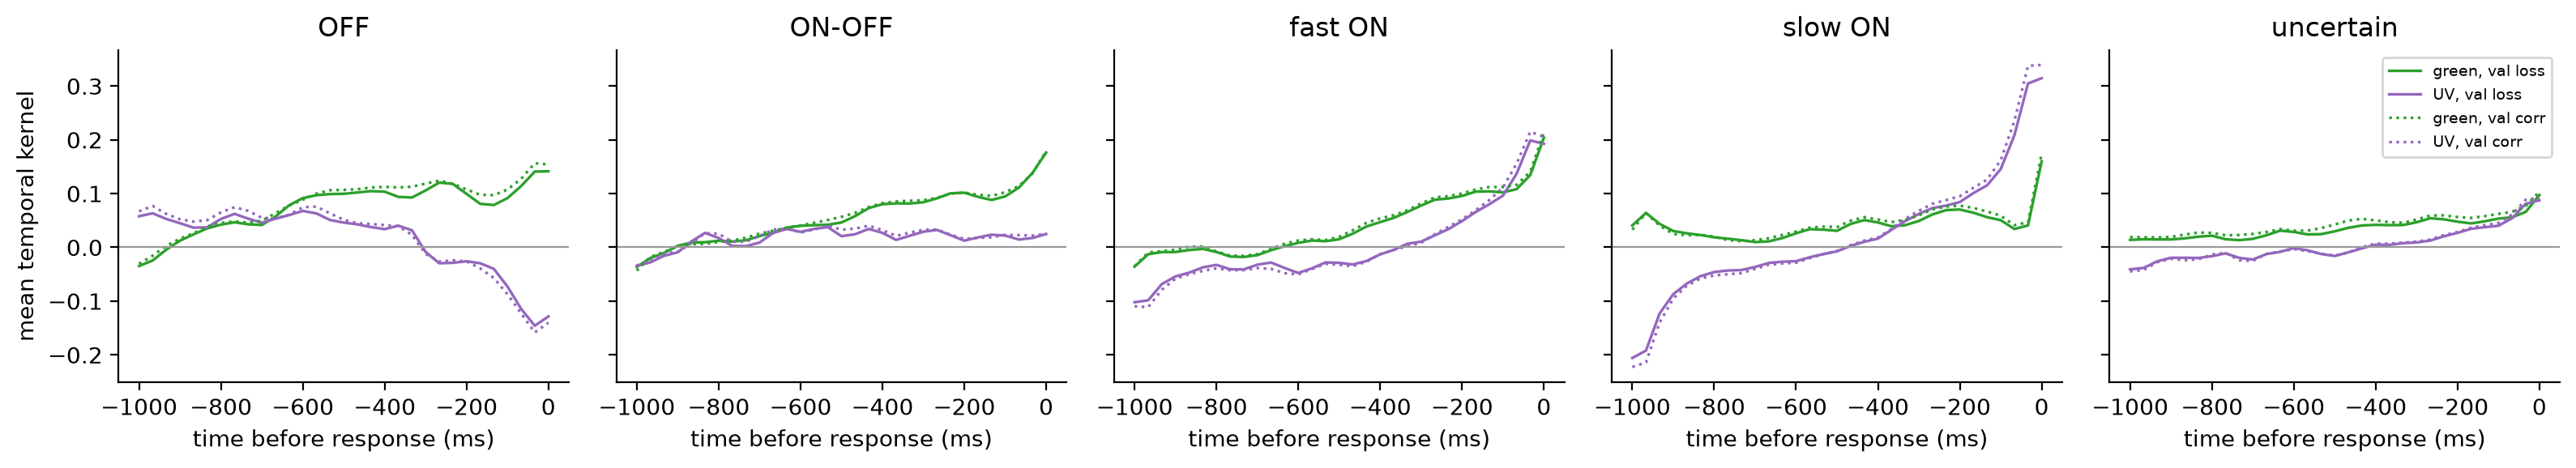

In [18]:
if COLOUR_FILTER_MODELS:
    all_groups = np.concatenate([final_responses[s].session_kwargs["group_assignment"] for s in sessions]).astype(int)
    fig, axes = plt.subplots(ncols=len(GROUPS), figsize=(3.2 * len(GROUPS), 3), sharey=True)
    for label in COLOUR_FILTER_MODELS:
        criterion = label.split(" · ")[1]
        model = models[label]
        temporal = np.concatenate(
            [
                np.stack([colour_filter_factors(model.readout[s], n)[1] for n in range(model.readout[s].number_of_neurons())])
                for s in sessions
            ]
        )  # (neurons, channels, time)
        for ax, (group_class, (first, last)) in zip(axes, GROUPS.items()):
            mean_kernels = temporal[(all_groups >= first) & (all_groups <= last)].mean(axis=0)
            for (channel, colour), kernel in zip(CHANNELS.items(), mean_kernels):
                ax.plot(lags_ms(len(kernel)), kernel, color=colour, ls=CRITERION_STYLES[criterion], lw=1.2,
                        label=f"{channel}, {criterion}")
    for ax, group_class in zip(axes, GROUPS):
        ax.axhline(0, color="0.6", lw=0.8)
        ax.set(title=group_class, xlabel="time before response (ms)")
    axes[0].set_ylabel("mean temporal kernel")
    axes[-1].legend(fontsize=7)
    sns.despine(fig=fig)
    fig.tight_layout()

## How far the learned filters moved

For each LN and SC model: how far the Gaussian's centre of mass moved from its start at the centre of the stimulus,
how its size changed (the RMS radius of the masked Gaussian, relative to the sigma = 1.5 start), how much the temporal
filter changed from its random start (1 - cosine similarity; about 1 means unrelated to the start), and the mean
temporal filter per functional group before (dashed) and after (solid) training. The mask is hard, at 1.5 sigma, so the
Gaussian gets gradient only from the pixels inside it: to reach a receptive field far from the centre it has to grow
first.

The LN and SC models have no temporal penalty, and their lag-30 temporal filters stay close to their random start
(median 1 - cosine 0.24-0.37, i.e. a cosine of about 0.7): the group means are smooth, the single-cell filters are
not. At lag 0 the single-frame filter keeps its random sign (1 - cosine = 0) in every cell.

,median centre shift (px),median size ratio,median temporal change
model,,,
LN Gaussian lag 0 · val corr,0.680379,1.155325,0.000000
LN Gaussian lag 0 · val loss,0.624002,1.143680,0.000000
LN Gaussian lag 30 · val corr,0.910420,1.035976,0.303878
LN Gaussian lag 30 · val loss,0.735062,1.045478,0.235594
SC lag 0 · val corr,0.747887,1.146101,0.000000
SC lag 0 · val loss,0.713993,1.150318,0.000000
SC lag 30 · val corr,0.947595,1.068537,0.320579
SC lag 30 · val loss,1.030569,1.063759,0.370411


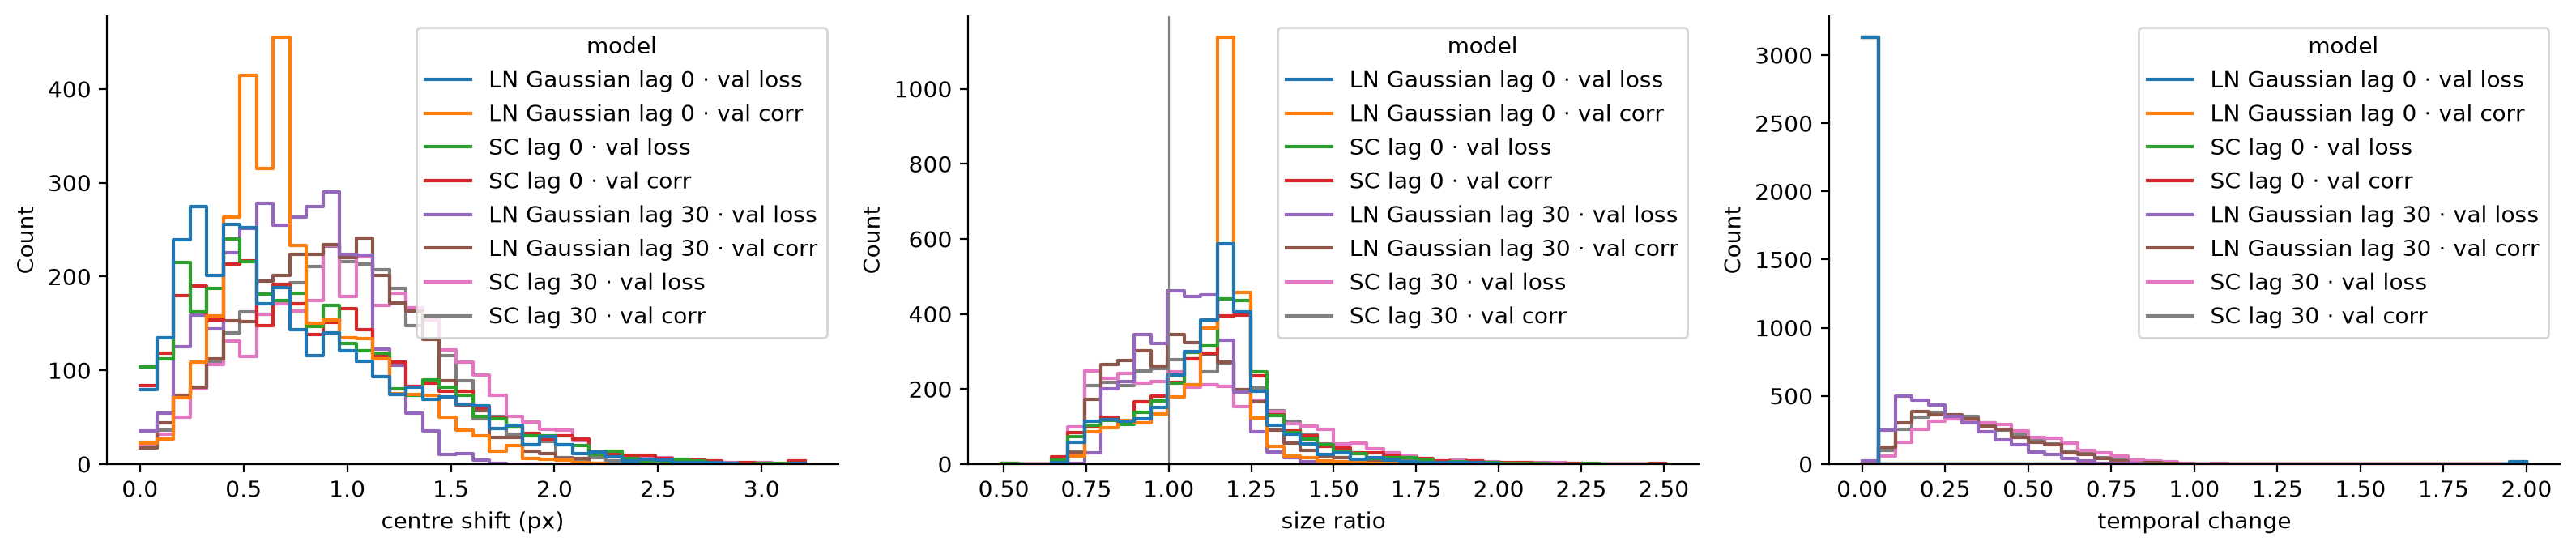

In [19]:
LEARNED_MODELS = [
    label
    for label, model in models.items()
    if any(isinstance(r, LearnableFilterSpatialContrastReadout) for r in model.readout.values())
]


def centre_and_size(spatial: np.ndarray) -> tuple[np.ndarray, np.ndarray]:
    """Centre of mass and RMS radius (pixels) of non-negative maps (N, H, W)."""
    weights = spatial / spatial.sum(axis=(1, 2), keepdims=True)
    y, x = np.mgrid[: spatial.shape[1], : spatial.shape[2]]
    cy, cx = (weights * y).sum(axis=(1, 2)), (weights * x).sum(axis=(1, 2))
    radius = np.sqrt((weights * ((y - cy[:, None, None]) ** 2 + (x - cx[:, None, None]) ** 2)).sum(axis=(1, 2)))
    return np.stack([cy, cx], axis=1), radius


movement_rows, temporal_rows = [], []
for label in LEARNED_MODELS:
    for session in sessions:
        readout = models[label].readout[session]
        with torch.no_grad():
            spatial, temporal, _ = readout._filters()
        active = readout.active.bool().cpu().numpy()
        centre, size = centre_and_size(spatial.cpu().numpy()[active])
        initial_centre, initial_size = centre_and_size(readout.spatial_filters.cpu().numpy()[active])
        learned_temporal = temporal.cpu().numpy()[active]
        initial_temporal = readout.temporal_filters.cpu().numpy()[active]
        cosine = (learned_temporal * initial_temporal).sum(axis=1) / (
            np.linalg.norm(learned_temporal, axis=1) * np.linalg.norm(initial_temporal, axis=1)
        )
        for shift, ratio, change in zip(np.linalg.norm(centre - initial_centre, axis=1), size / initial_size, 1 - cosine):
            movement_rows.append(
                {"model": label, "centre shift (px)": shift, "size ratio": ratio, "temporal change": change}
            )
        groups = final_responses[session].session_kwargs["group_assignment"]
        for neuron in range(len(groups)):
            temporal_rows.append(
                {"model": label, "group": int(groups[neuron]), "stage": "learned", "filter": temporal[neuron].cpu().numpy()}
            )
            temporal_rows.append(
                {
                    "model": label,
                    "group": int(groups[neuron]),
                    "stage": "initial",
                    "filter": readout.temporal_filters[neuron].cpu().numpy(),
                }
            )
movement = pd.DataFrame(movement_rows)

if LEARNED_MODELS:
    fig, axes = plt.subplots(ncols=3, figsize=(16, 3.5))
    sns.histplot(data=movement, x="centre shift (px)", hue="model", element="step", fill=False, ax=axes[0], bins=40)
    sns.histplot(data=movement, x="size ratio", hue="model", element="step", fill=False, ax=axes[1], bins=40)
    sns.histplot(data=movement, x="temporal change", hue="model", element="step", fill=False, ax=axes[2], bins=40)
    axes[1].axvline(1, color="0.5", lw=0.8)
    sns.despine(fig=fig)
    fig.tight_layout()
    display(movement.groupby("model").median().rename(columns=lambda c: f"median {c}"))

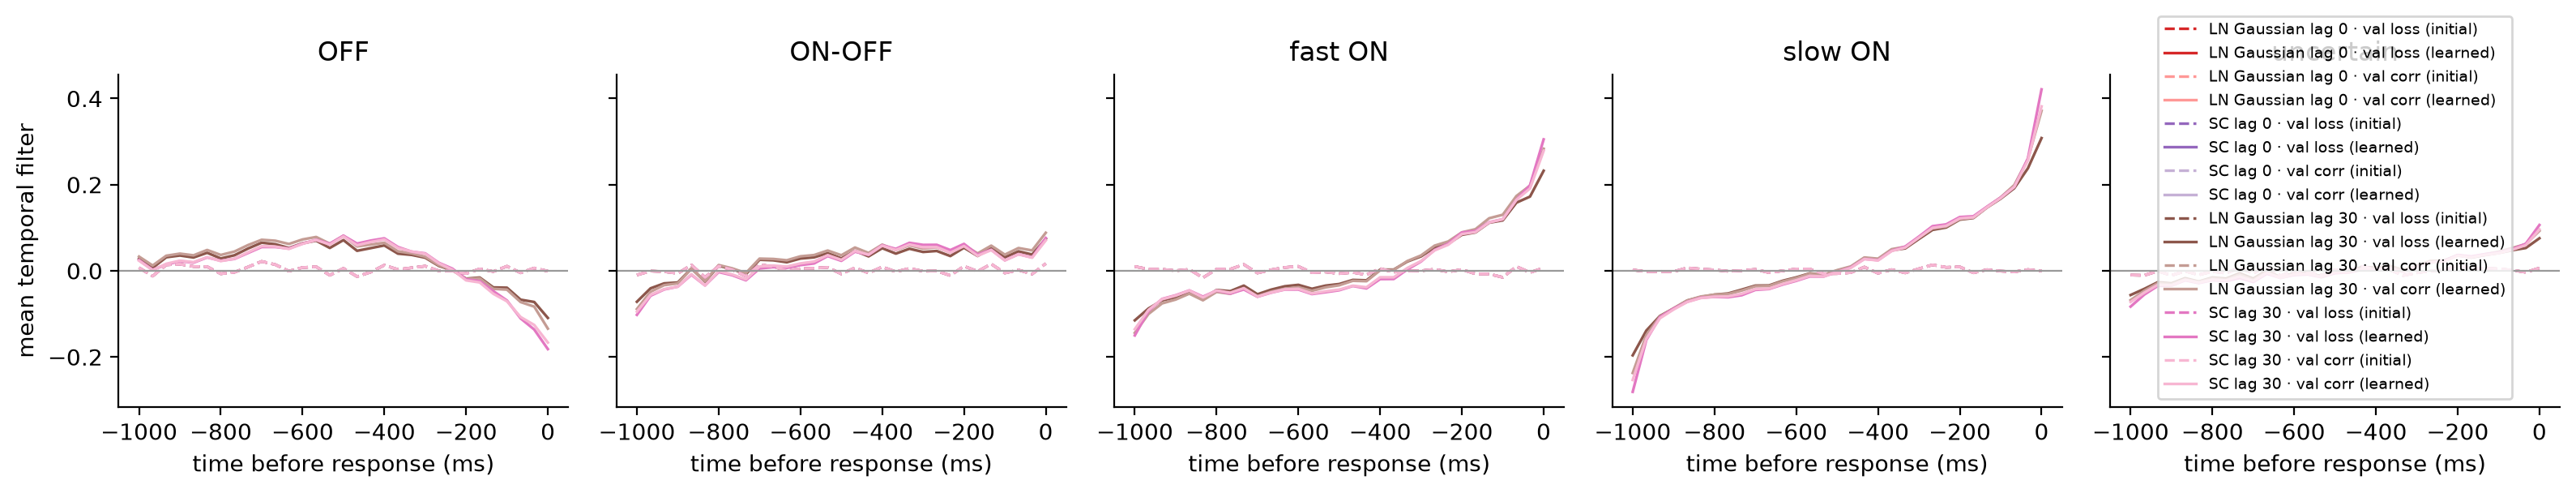

In [20]:
if LEARNED_MODELS:
    temporal_df = pd.DataFrame(temporal_rows)
    temporal_df["group_class"] = pd.cut(
        temporal_df["group"], bins=[0, 9, 14, 20, 28, 32], labels=list(GROUPS), include_lowest=True
    )
    fig, axes = plt.subplots(ncols=len(GROUPS), figsize=(3.2 * len(GROUPS), 3), sharey=True)
    for ax, group_class in zip(axes, GROUPS):
        for label in LEARNED_MODELS:
            for stage, style in [("initial", "--"), ("learned", "-")]:
                selection = temporal_df[
                    (temporal_df.model == label) & (temporal_df.stage == stage) & (temporal_df.group_class == group_class)
                ]
                if selection.empty:
                    continue
                mean_filter = np.stack(selection["filter"].to_list()).mean(axis=0)
                ax.plot(lags_ms(len(mean_filter)), mean_filter, ls=style, color=palette[label], lw=1.2,
                        label=f"{label} ({stage})")
        ax.axhline(0, color="0.6", lw=0.8)
        ax.set(title=group_class, xlabel="time before response (ms)")
    axes[0].set_ylabel("mean temporal filter")
    axes[-1].legend(fontsize=7)
    sns.despine(fig=fig)
    fig.tight_layout()

## Why the temporal filters peak at the current frame

This section is about the earlier lag-30 LNP ("current-frame init", `lnp_grey_separable_t31/tsmooth0`), whose
temporal kernel starts as a delta on the current frame, and the LN and SC models that used to start from its filters.
They all have a large temporal weight on the current frame (0 ms) and an opposite-sign weight on the frame before. Two
things are behind this.

**The opposite-sign pair is left over from the initialisation.** The LNP's temporal kernel starts as a delta on the
current frame (1 there, 0 elsewhere), i.e. as the lag-0 LNP. Natural movies change little from one frame to the next,
so the responses pin down the *sum* of two neighbouring weights much better than their *difference*. After training,
the difference between the current and the previous frame's weight is still close to its starting value in every
cell, while their sum varies from cell to cell, and replacing both weights by their mean, which keeps the sum, leaves
the test correlation unchanged (tables below). Retrained from a uniform start, the opposite sign on the previous frame
disappears (next subsection). The earlier LN and SC models started from the LNP's filters and trained them slowly, so they
inherited the pair; the models above start from random filters instead.

**The weight on the newest frames is not an artefact.** It remains in the uniform-start LNP, where the current frame
still carries the most weight in most cells. The responses are one reason: they are spikes inferred from calcium
imaging, which anticipate the stimulus (last subsection), so the frames just before each response matter most to a
causal model. Trained on the calcium traces instead, the uniform-start LNP's temporal filters mostly peak 100-300 ms
back.

Temporal weights as stored (the spatial filter carries the polarity there) of the current-frame-init LNP and of the
random-init LNP of this notebook, and the current-frame-init LNP's median test correlation over reliable cells as
learned and with the current and previous frame's weights replaced by their mean:

In [21]:
def with_current_and_previous_averaged(model):
    """Copy of a separable LNP whose current and previous frame's temporal weights are replaced by their mean."""
    changed = copy.deepcopy(model)
    with torch.no_grad():
        for readout in changed.readout.values():
            weight = readout.temporal_kernel.weight  # (neurons, 1, time, 1, 1); index -1 is the current frame
            mean = (weight[:, :, -1] + weight[:, :, -2]) / 2
            weight[:, :, -1], weight[:, :, -2] = mean, mean.clone()
    return changed


def test_correlations(model) -> np.ndarray:
    """Correlation of each neuron's prediction with its trial-averaged test response, sessions in order."""
    correlations = []
    for session in sessions:
        test_movie = dataloaders["test"][session].dataset.movies
        with torch.no_grad():
            prediction = model(test_movie.to(model.device).unsqueeze(0), data_key=session).squeeze(0).cpu().numpy()
        target = final_responses[session].test_response.T
        correlations.append(correlation_numpy(target[len(target) - len(prediction) :], prediction, axis=0))
    return np.concatenate(correlations)


def raw_temporal_weights(model) -> np.ndarray:
    """Temporal kernels as stored (neurons, time), sessions in order; index -1 is the current frame."""
    return np.concatenate([model.readout[s].temporal_kernel.weight[:, 0, :, 0, 0].detach().cpu().numpy() for s in sessions])


delta_checkpoint = resolve_checkpoint(DIAGNOSTIC_LNPS["current-frame init"])
if delta_checkpoint is not None:
    delta_lnp = load_core_readout_model(delta_checkpoint, device).eval()
    weight_models = {"current-frame init": delta_lnp}
    if REFERENCE_MODEL in models:
        weight_models[f"random init ({REFERENCE_MODEL})"] = models[REFERENCE_MODEL]
    weight_quantiles = {}
    for label, model in weight_models.items():
        weights = raw_temporal_weights(model)
        weight_quantiles[label] = (
            pd.DataFrame(
                {
                    "current frame": weights[:, -1],
                    "previous frame": weights[:, -2],
                    "current - previous": weights[:, -1] - weights[:, -2],
                    "current + previous": weights[:, -1] + weights[:, -2],
                }
            )
            .quantile([0.25, 0.5, 0.75])
            .rename(index=lambda q: f"{q:.0%} quantile")
        )
    display(pd.concat(weight_quantiles).round(3))
    reliable_mask = metrics.loc[metrics["model"] == next(iter(models)), "reliable"].to_numpy()  # same cell order
    variants = {
        "as learned": delta_lnp,
        "current and previous frame averaged": with_current_and_previous_averaged(delta_lnp),
    }
    display(
        pd.DataFrame(
            {label: [np.median(test_correlations(model)[reliable_mask])] for label, model in variants.items()},
            index=["current-frame init LNP, median test correlation"],
        ).round(3)
    )

current frame  \
current-frame init                       25% quantile          0.577   
                                         50% quantile          0.631   
                                         75% quantile          0.672   
random init (LNP grey lag 30 · val loss) 25% quantile         -0.085   
                                         50% quantile         -0.001   
                                         75% quantile          0.086   

                                                       previous frame  \
current-frame init                       25% quantile          -0.273   
                                         50% quantile          -0.229   
                                         75% quantile          -0.181   
random init (LNP grey lag 30 · val loss) 25% quantile          -0.102   
                                         50% quantile          -0.000   
                                         75% quantile           0.101   

                                                       current - previous  \
current-frame init                       25% quantile               0.805   
                                         50% quantile               0.852   
                                         75% quantile               0.891   
random init (LNP grey lag 30 · val loss) 25% quantile              -0.029   
                                         50% quantile               0.000   
                                         75% quantile               0.032   

                                                       current + previous  
current-frame init                       25% quantile               0.308  
                                         50% quantile               0.401  
                                         75% quantile               0.483  
random init (LNP grey lag 30 · val loss) 25% quantile              -0.186  
                                         50% quantile              -0.001  
                                         75% quantile               0.192

,as learned,current and previous frame averaged
"current-frame init LNP, median test correlation",0.402,0.405


### Retraining without the delta

The lag-30 LNP retrained with every frame starting at the same weight, 1/31 (`+model.readout.temporal_init=uniform`),
next to the original (current-frame init) and the random-init LNP of this notebook (selected on each criterion, and without its temporal smoothness). Both were also trained on responses delayed by a few frames
(`data_io.responses.response_delay_frames`) and on the calcium traces (`+data_io.responses.trace_type=preprocessed`),
to see how much of the current-frame weight follows the response timing. The figure shows the mean temporal filter per
group against time from the recorded response, so a delayed model's filter is shifted right by its delay. The table
gives where each cell's temporal filter peaks, and each model's median test correlation over reliable cells. Only the
models trained on the undelayed spikes are scored against the Table 2 targets; the others are scored on their own
responses (delayed, or calcium), which are not comparable.

The uniform start removes the opposite-sign pair, but leaves a negative weight on the oldest frames instead (where
the median peak of its delayed version lands). The random-init LNPs of this notebook peak on the current frame in
only 12-13% of cells (16% without temporal smoothing), with a median peak 167 ms before the response, and have no
opposite-sign pair either. Delaying the responses moves weight away from the current frame without improving the
predictions, so the response timing explains part of the current-frame weight, not all of it.

,delay (frames),peak on current frame,current and previous frame opposite,median peak (ms from response),median test corr,scored on
model,,,,,,
current-frame init,0,0.997,0.999,0.000,0.402,Table 2 targets
delay 3 frames,3,0.997,1.000,100.000,0.401,own responses
delay 6 frames,6,0.957,1.000,200.000,0.395,own responses
delay 9 frames,9,0.967,1.000,300.000,0.380,own responses
calcium,0,0.957,1.000,0.000,0.518,own responses
uniform init,0,0.736,0.043,0.000,0.388,Table 2 targets
"uniform init, delay 6 frames",6,0.361,0.065,-800.000,0.392,own responses
"uniform init, calcium",0,0.215,0.246,-300.000,0.518,own responses
"random init, unsmoothed, val corr",0,0.162,0.346,-233.333,0.394,Table 2 targets


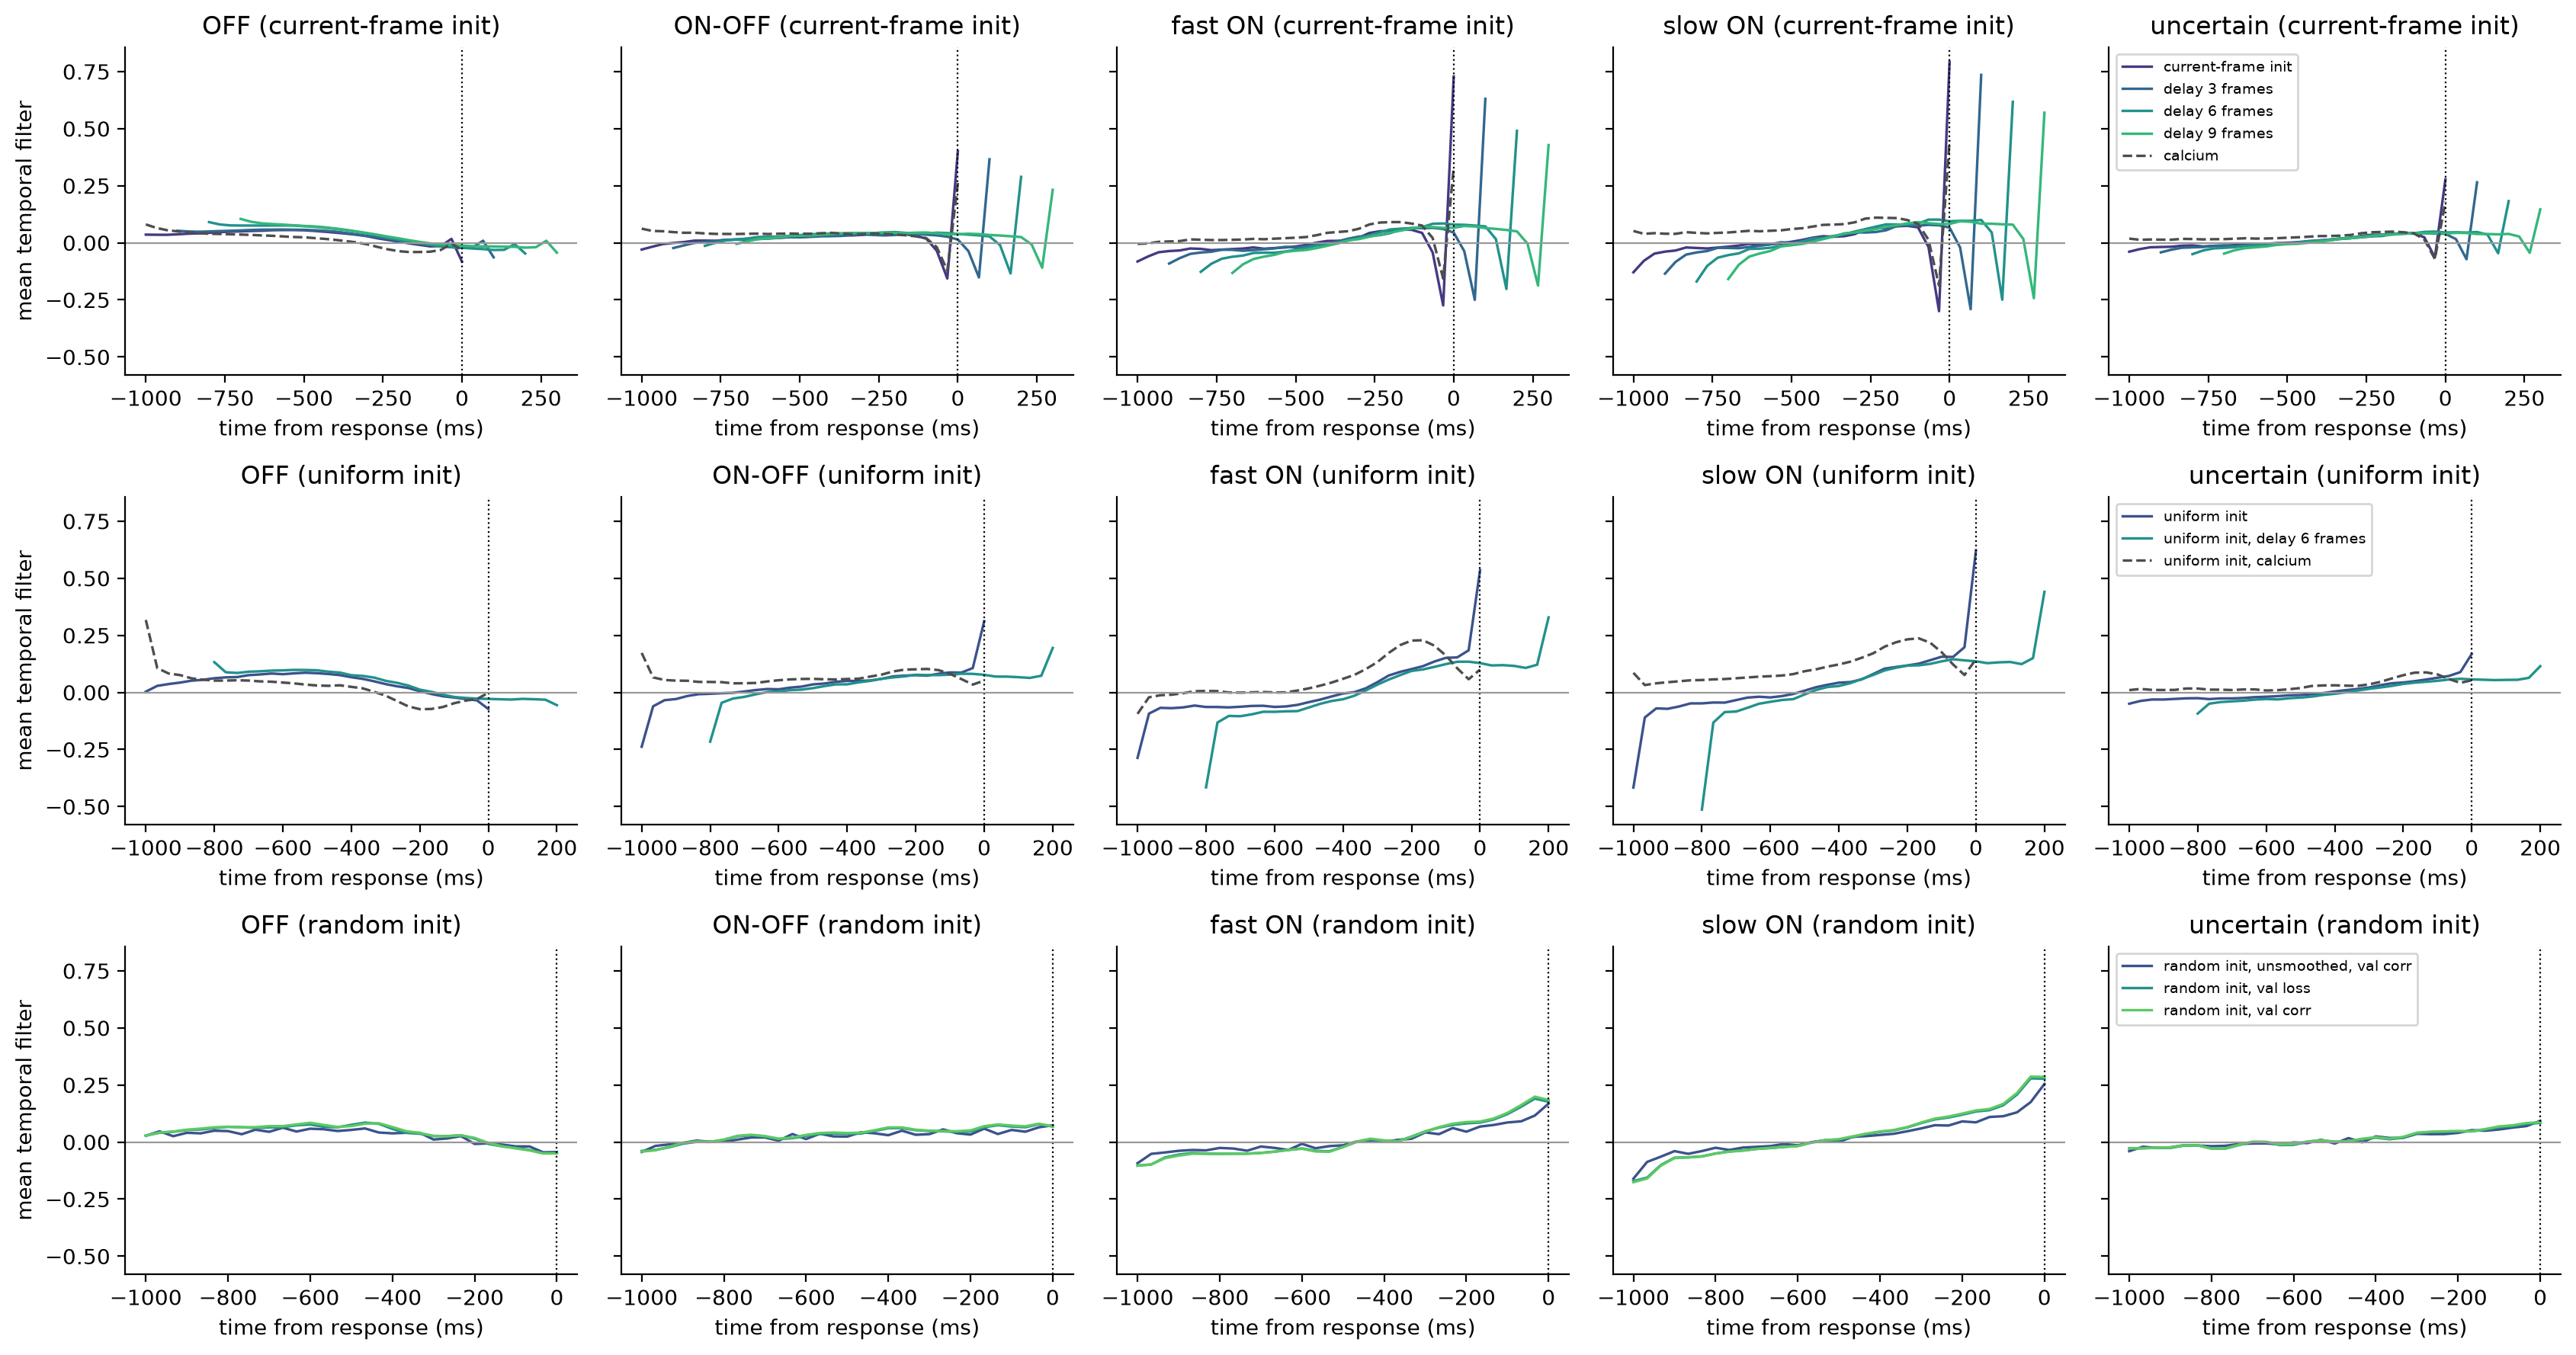

In [22]:
diagnostic_models = {}
for label, location in DIAGNOSTIC_LNPS.items():
    checkpoint = resolve_checkpoint(location)
    if checkpoint is None:
        print(f"skipping {label}: nothing at {location}")
        continue
    diagnostic_models[label] = load_core_readout_model(checkpoint, device).eval()
for criterion in CRITERIA:
    if f"LNP grey lag 30 · {criterion}" in models:
        diagnostic_models[f"random init, {criterion}"] = models[f"LNP grey lag 30 · {criterion}"]

all_groups = np.concatenate([final_responses[s].session_kwargs["group_assignment"] for s in sessions]).astype(int)
reliable_mask = metrics.loc[metrics["model"] == next(iter(models)), "reliable"].to_numpy()
summary_rows, mean_filters = [], {}
for label, model in diagnostic_models.items():
    delay = int(model.data_info.get("response_delay_frames", 0))
    on_table2_targets = delay == 0 and "calcium" not in label
    temporal = np.concatenate(
        [
            np.stack([lnp_filter_factors(model.readout[s], n)[1] for n in range(model.readout[s].number_of_neurons())])
            for s in sessions
        ]
    )  # (neurons, time), unit norm, polarity in the temporal filter; index -1 is the current frame
    frames_before = temporal.shape[1] - 1 - np.abs(temporal).argmax(axis=1)  # where each filter peaks
    if on_table2_targets:
        correlations = test_correlations(model)
    else:
        correlations = np.concatenate(
            [torch.as_tensor(model.data_info["pretrained_performance"][s]).cpu().numpy() for s in sessions]
        )
    summary_rows.append(
        {
            "model": label,
            "delay (frames)": delay,
            "peak on current frame": np.mean(frames_before == 0),
            "current and previous frame opposite": np.mean(np.sign(temporal[:, -1]) != np.sign(temporal[:, -2])),
            "median peak (ms from response)": np.median(delay - frames_before) * 1000 / FRAME_RATE_HZ,
            "median test corr": np.median(correlations[reliable_mask]),
            "scored on": "Table 2 targets" if on_table2_targets else "own responses",
        }
    )
    mean_filters[label] = (
        lags_ms(temporal.shape[1]) + delay * 1000 / FRAME_RATE_HZ,
        {c: temporal[(all_groups >= lo) & (all_groups <= hi)].mean(axis=0) for c, (lo, hi) in GROUPS.items()},
    )

display(pd.DataFrame(summary_rows).set_index("model").round(3))

# One row per temporal initialisation
rows = {
    "current-frame init": [label for label in mean_filters if "uniform" not in label and "random" not in label],
    "uniform init": [label for label in mean_filters if "uniform" in label],
    "random init": [label for label in mean_filters if "random" in label],
}
rows = {title: labels for title, labels in rows.items() if labels}
fig, axes = plt.subplots(
    nrows=len(rows), ncols=len(GROUPS), figsize=(3.4 * len(GROUPS), 3.0 * len(rows)), sharey=True, squeeze=False
)
for row_axes, (title, labels) in zip(axes, rows.items()):
    colors = sns.color_palette("viridis", n_colors=len(labels))
    for color, label in zip(colors, labels):
        times_ms, by_class = mean_filters[label]
        style = {"color": "0.3", "ls": "--"} if "calcium" in label else {"color": color, "ls": "-"}
        for ax, group_class in zip(row_axes, GROUPS):
            ax.plot(times_ms, by_class[group_class], lw=1.2, label=label, **style)
    for ax, group_class in zip(row_axes, GROUPS):
        ax.axvline(0, color="k", lw=0.8, ls=":")
        ax.axhline(0, color="0.6", lw=0.8)
        ax.set(title=f"{group_class} ({title})", xlabel="time from response (ms)")
    row_axes[0].set_ylabel("mean temporal filter")
    row_axes[-1].legend(fontsize=7)
sns.despine(fig=fig)
fig.tight_layout()

### Timing of the inferred spikes

Separately from the initialisation, the responses all these models fit are spikes inferred from calcium imaging at
7.8 Hz and interpolated to the 30 Hz stimulus frames, and spike inference is not causal. Around the chirp's light steps
below, the inferred spikes start rising ~200 ms *before* the step, while the calcium signal they are inferred from only
rises after it. A response at frame t therefore partly reflects frames after t, so the timing of a filter relative to
the response is not a physiological latency. This holds for every Table 2 model, the CNN included.

Average calcium signal and inferred spikes around the light-on step (ON cells) and the light-off step (OFF cells) of
the chirp, over the analysed cells and all chirp repeats:

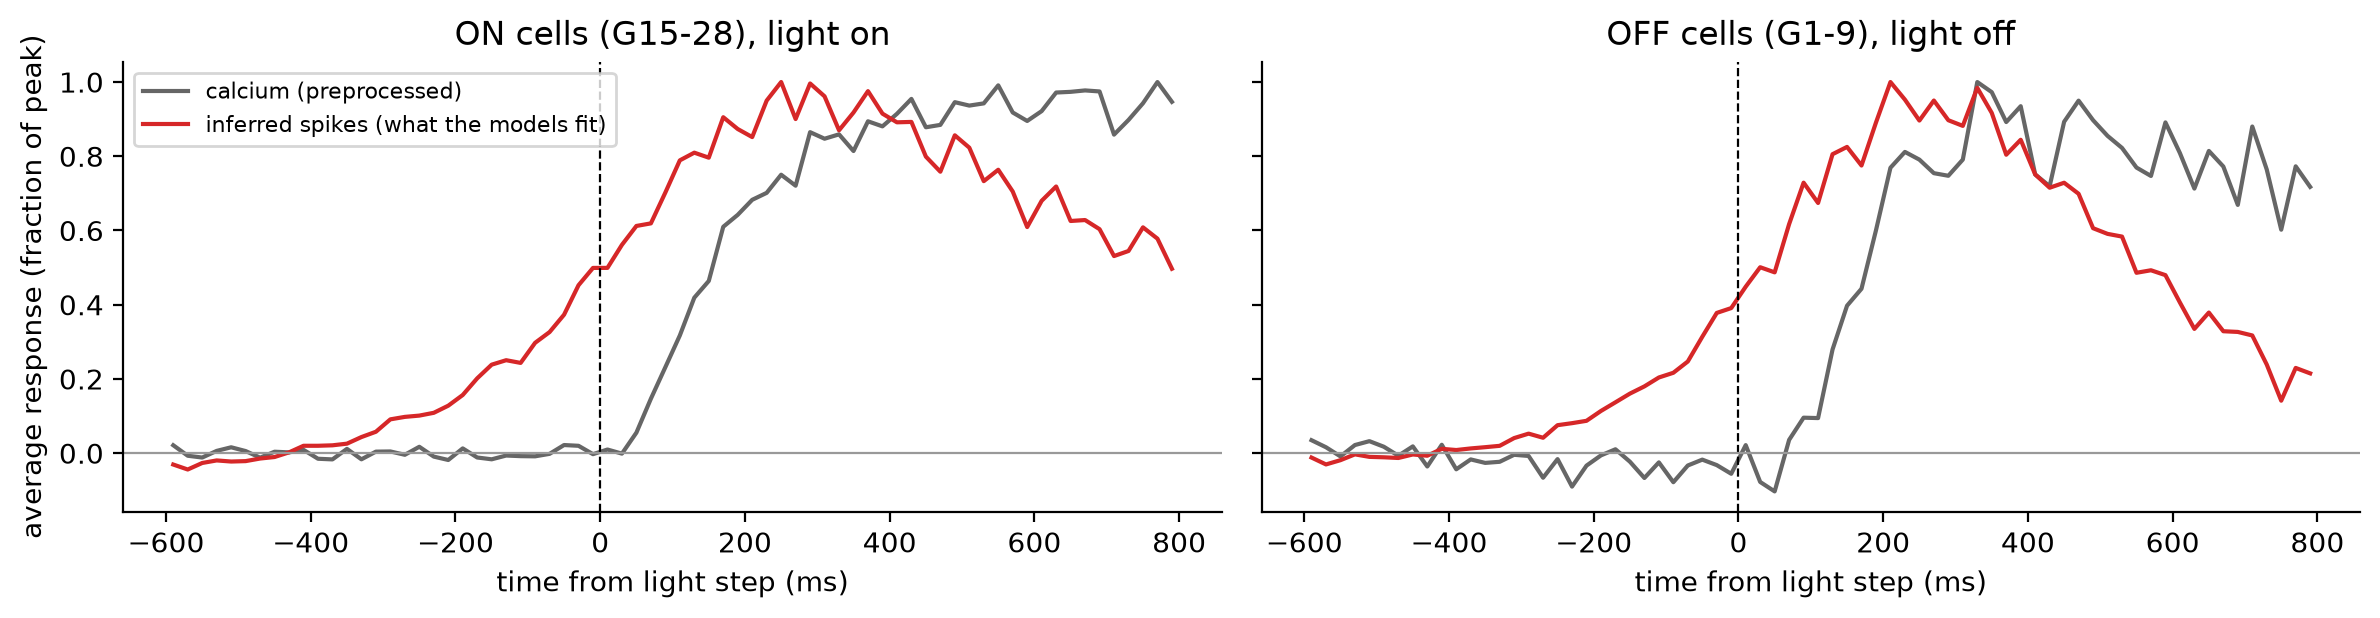

In [23]:
CHIRP_STEPS = {  # cells (first and last group) and the light step they respond to
    "ON cells (G15-28), light on": (15, 28, "on"),
    "OFF cells (G1-9), light off": (1, 9, "off"),
}
CHIRP_SIGNALS = {  # signal: (traces, their time stamps) in the responses file
    "calcium (preprocessed)": ("chirp_preprocessed_traces", "chirp_traces_times"),
    "inferred spikes (what the models fit)": ("chirp_spikes", "chirp_spike_times"),
}
STEP_BINS = np.arange(-0.6, 0.8001, 0.02)  # s around the step


def step_average(traces_key: str, times_key: str, first_group: int, last_group: int, step: str) -> np.ndarray:
    """Average of a chirp signal around a light step, over the analysed cells of some groups and all chirp repeats.

    Each cell is scaled by its standard deviation, and each repeat baseline-subtracted over 0.6 to 0.3 s before the
    step (later than that, the inferred spikes are already rising). Every cell is sampled at 7.8 Hz at its own phase,
    so pooling cells resolves the average more finely than that.
    """
    total, count = np.zeros(len(STEP_BINS) - 1), np.zeros(len(STEP_BINS) - 1)
    for session in sessions:
        raw = responses_dict[session]
        groups = final_responses[session].session_kwargs["group_assignment"]
        roi_ids = final_responses[session].session_kwargs["roi_ids"][(groups >= first_group) & (groups <= last_group)]
        # Two triggers per chirp: its start, and the light-off step 5 s in, after 2 s dark and 3 s light
        triggers = raw["chirp_trigger_times"][0]
        starts, light_off = triggers[::2], triggers[1::2]
        step_times = starts + 0.4 * (light_off - starts) if step == "on" else light_off
        for row in np.flatnonzero(np.isin(raw["roi_ids"], roi_ids.astype(int))):
            trace, times = raw[traces_key][row].astype(float), raw[times_key][row]
            valid = np.isfinite(trace)
            trace, times = trace[valid] / (trace[valid].std() + 1e-9), times[valid]
            for step_time in step_times:
                relative = times - step_time
                baseline = trace[(relative >= STEP_BINS[0]) & (relative < -0.3)]
                inside = (relative >= STEP_BINS[0]) & (relative < STEP_BINS[-1])
                if baseline.size == 0:
                    continue
                bins = np.digitize(relative[inside], STEP_BINS) - 1
                np.add.at(total, bins, trace[inside] - baseline.mean())
                np.add.at(count, bins, 1)
    return total / np.maximum(count, 1)


step_centres_ms = 1000 * (STEP_BINS[:-1] + STEP_BINS[1:]) / 2
fig, axes = plt.subplots(ncols=len(CHIRP_STEPS), figsize=(6 * len(CHIRP_STEPS), 3.2), sharey=True)
for ax, (title, (first_group, last_group, step)) in zip(axes, CHIRP_STEPS.items()):
    for (label, (traces_key, times_key)), color in zip(CHIRP_SIGNALS.items(), ["0.4", "C3"]):
        average = step_average(traces_key, times_key, first_group, last_group, step)
        ax.plot(step_centres_ms, average / np.abs(average).max(), color=color, label=label)
    ax.axvline(0, color="k", lw=0.8, ls="--")
    ax.axhline(0, color="0.6", lw=0.8)
    ax.set(title=title, xlabel="time from light step (ms)")
axes[0].set_ylabel("average response (fraction of peak)")
axes[0].legend(fontsize=8, loc="upper left")
sns.despine(fig=fig)
fig.tight_layout()

# Predictions

Recorded responses to the test movie (grey: the three repeats, black: their mean) with each model's prediction. The
shaded start is cut by every model; dotted lines separate the five test clips.

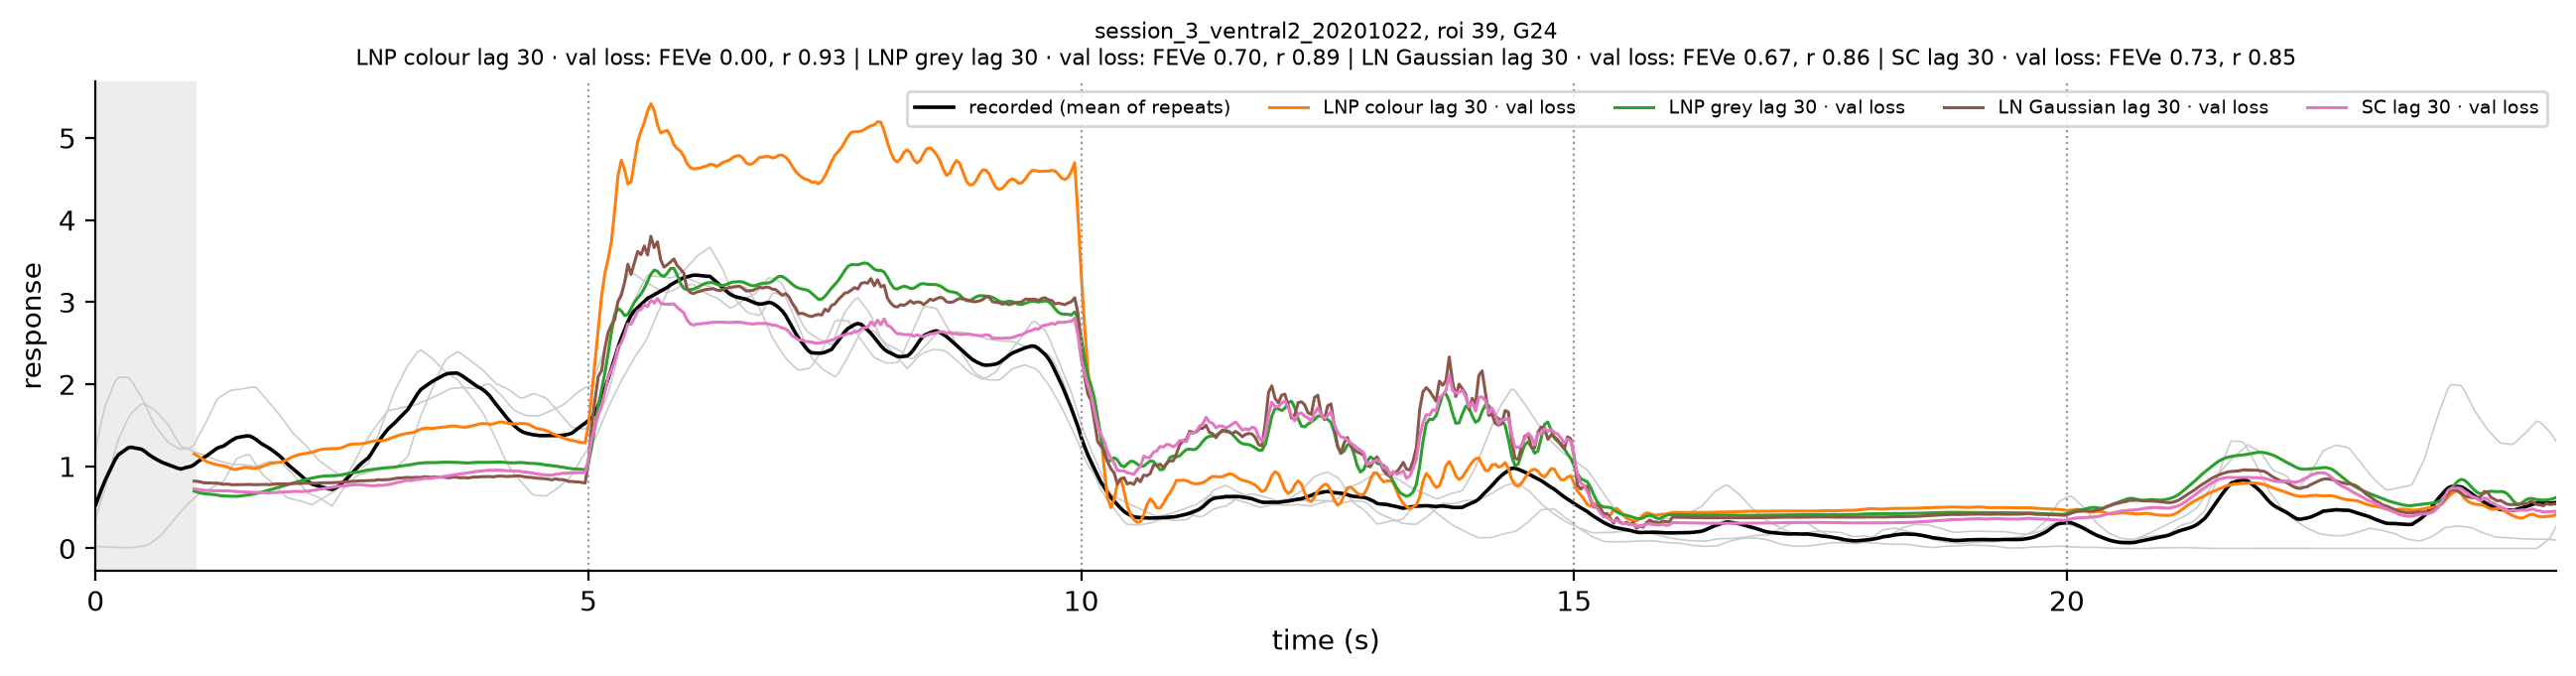

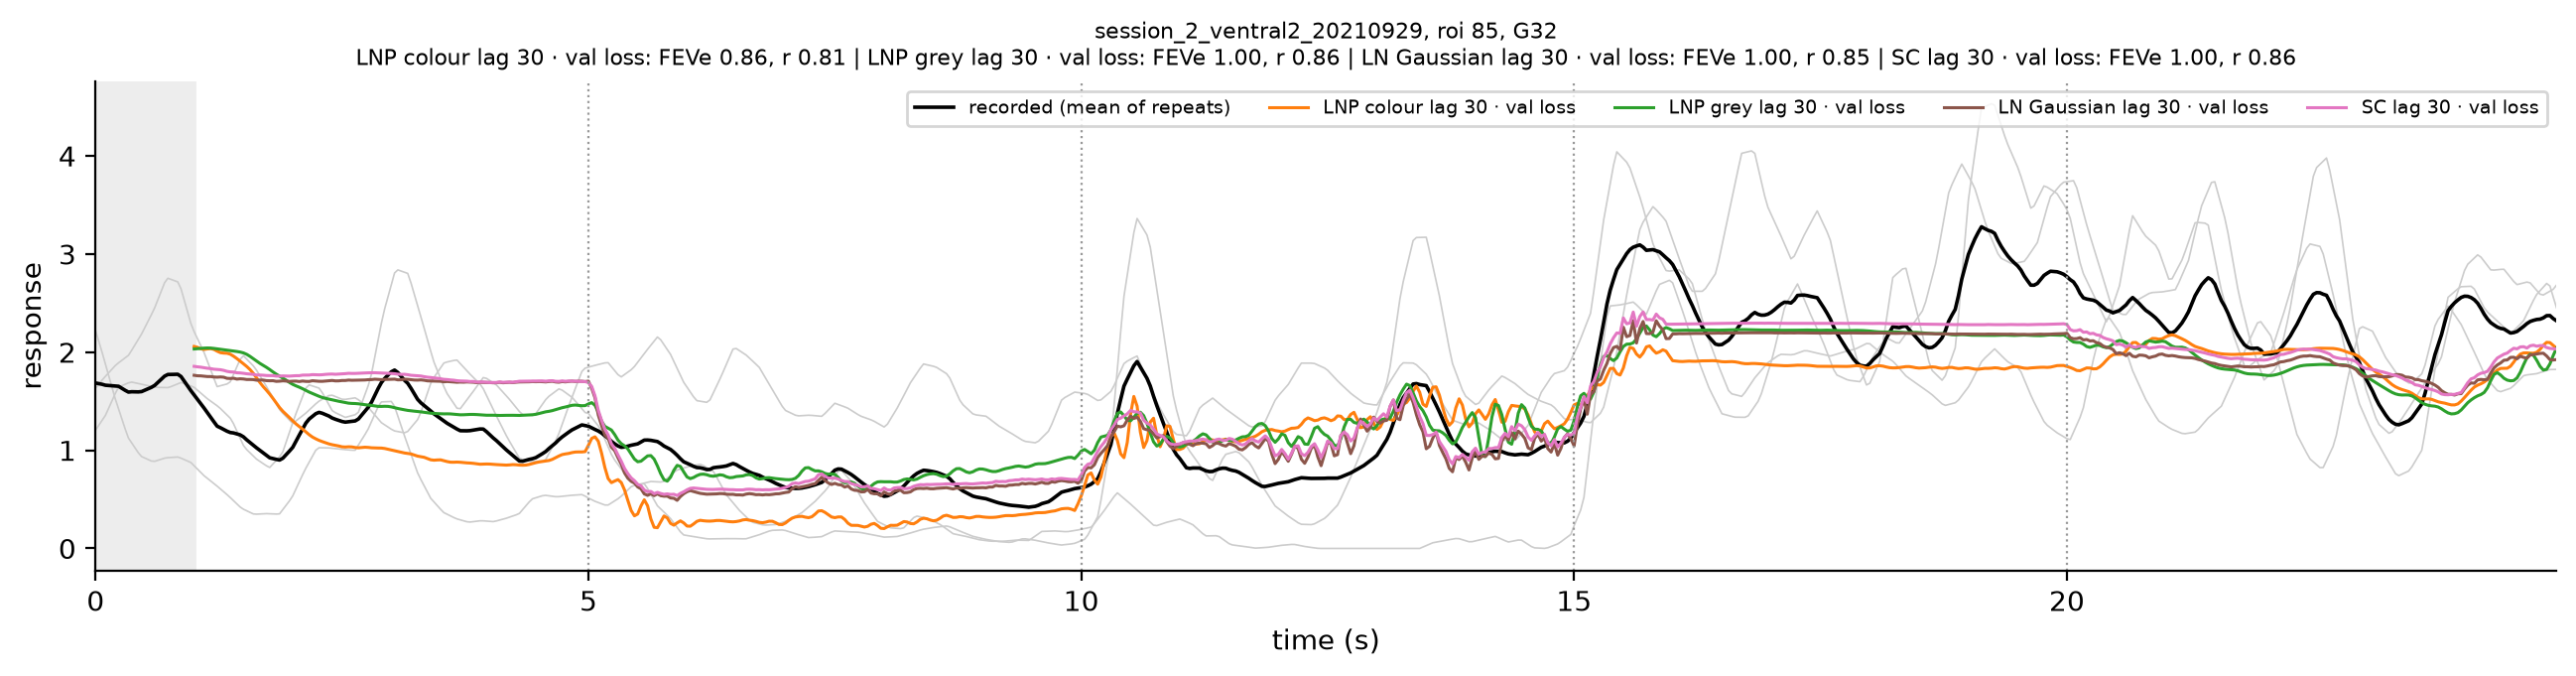

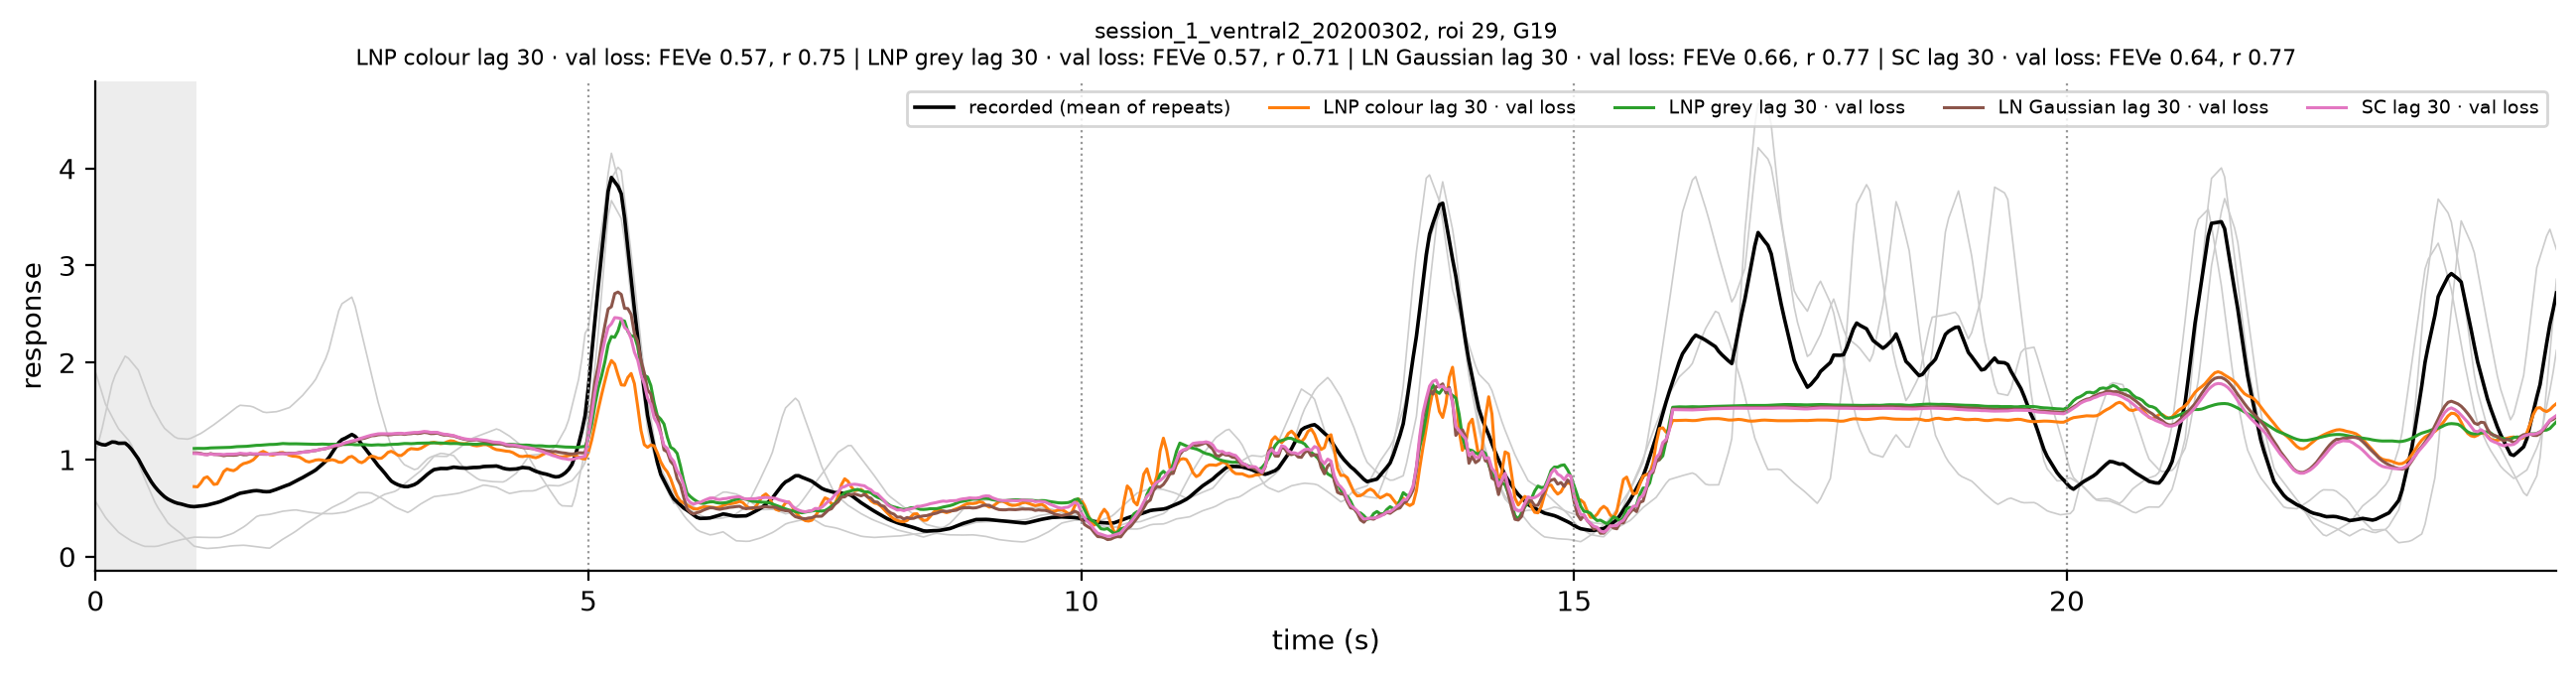

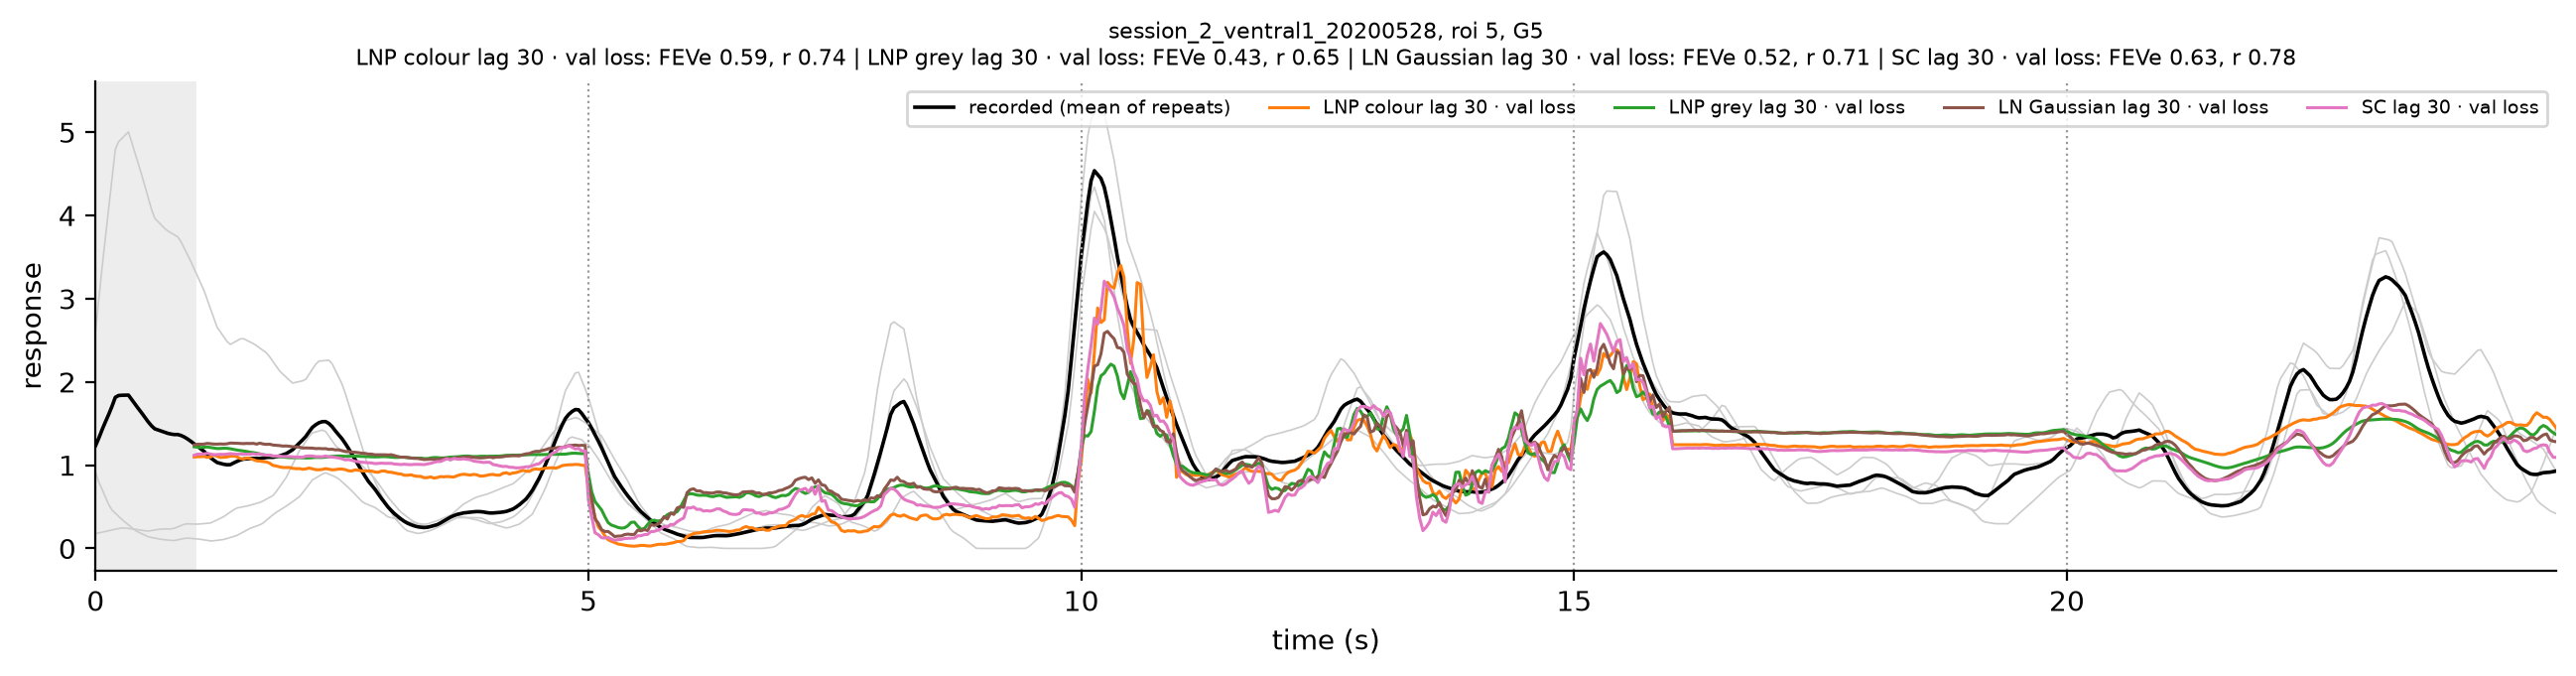

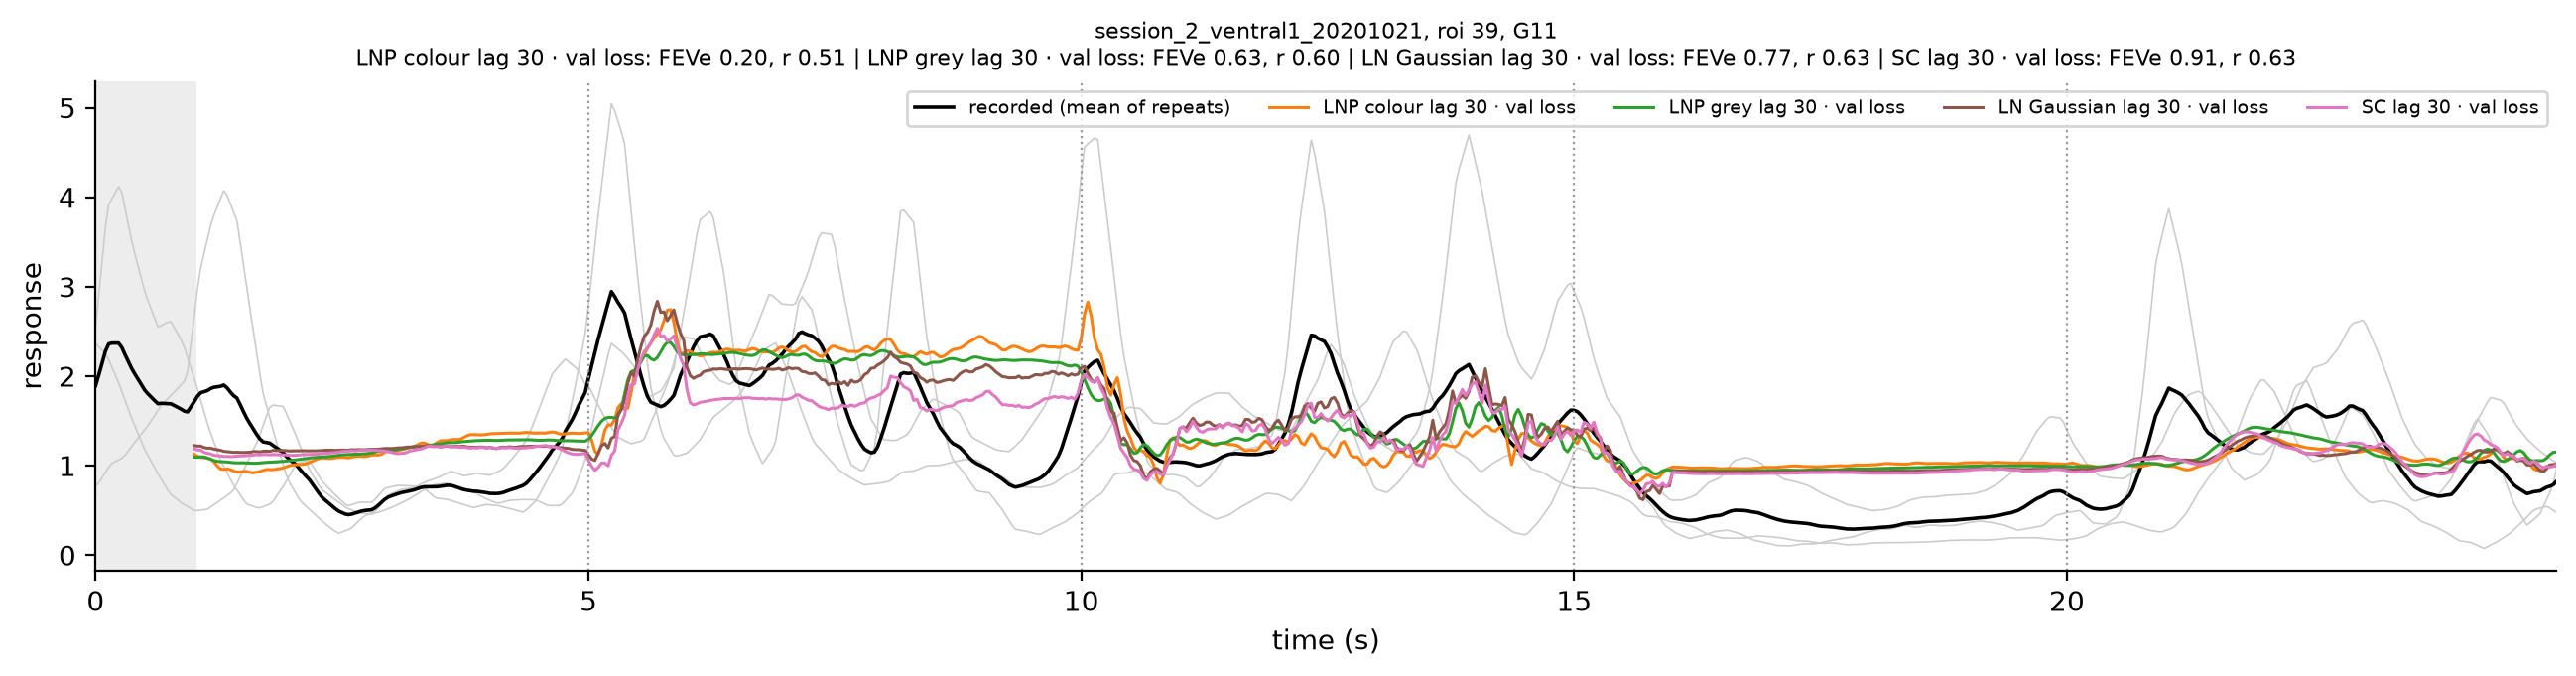

In [24]:
def plot_cell_predictions(session: str, neuron: int, model_labels: list[str], ax: plt.Axes | None = None) -> plt.Figure:
    if ax is None:
        _, ax = plt.subplots(figsize=(16, 3.2))
    by_trial = final_responses[session].test_by_trial[neuron]  # (time, trials)
    time_s = np.arange(by_trial.shape[0]) / FRAME_RATE_HZ
    ax.plot(time_s, by_trial, color="0.8", lw=0.6)
    ax.plot(time_s, by_trial.mean(axis=1), color="k", lw=1.3, label="recorded (mean of repeats)")

    scores = []
    for label in model_labels:
        prediction = predictions[label][session][:, neuron]
        lag = len(time_s) - len(prediction)
        ax.plot(time_s[lag:], prediction, color=palette[label], lw=1.1, label=label)
        row = metrics[(metrics.model == label) & (metrics.session == session) & (metrics.neuron == neuron)].iloc[0]
        scores.append(f"{label}: FEVe {row.feve:.2f}, r {row.correlation:.2f}")
    ax.axvspan(0, lag / FRAME_RATE_HZ, color="0.93", zorder=0)
    for boundary in range(CLIP_LENGTH, by_trial.shape[0], CLIP_LENGTH):
        ax.axvline(boundary / FRAME_RATE_HZ, color="0.6", ls=":", lw=0.8)

    info = cell_info.loc[(session, neuron)]
    ax.set_title(f"{session}, roi {info.roi_id}, G{info.group}\n" + " | ".join(scores), fontsize=8)
    ax.set(xlabel="time (s)", ylabel="response", xlim=(0, time_s[-1]))
    ax.legend(fontsize=7, loc="upper right", ncols=len(model_labels) + 1)
    sns.despine(ax=ax)
    return ax.figure


for session, neuron in example_cells:
    plot_cell_predictions(session, neuron, TRACE_MODELS)
    plt.show()

In [25]:
def export_all_predictions(directory: str | Path, model_labels: list[str], file_format: str = "png") -> None:
    """One figure per cell, named <session>_roi<roi id>_G<group>.<format>."""
    directory = Path(directory)
    directory.mkdir(parents=True, exist_ok=True)
    for session in sessions:
        for neuron in range(predictions[model_labels[0]][session].shape[1]):
            figure = plot_cell_predictions(session, neuron, model_labels)
            info = cell_info.loc[(session, neuron)]
            figure.savefig(directory / f"{session}_roi{info.roi_id}_G{info.group}.{file_format}", bbox_inches="tight", dpi=150)
            plt.close(figure)
    print(f"saved {len(cell_info)} figures to {directory}")


if TRACE_EXPORT_DIR is not None:
    export_all_predictions(TRACE_EXPORT_DIR, TRACE_MODELS, TRACE_EXPORT_FORMAT)

# The contrast weight `w`

`w` scales the local spatial contrast term against the spatially weighted mean intensity: `w > 0` means contrast inside
the receptive field drives the cell beyond what its mean input explains. The LN variants fix `w = 0` and are left out.
The lag-0 and lag-30 SC models are compared under both selection criteria.

In [26]:
w_columns = {}
for label in W_MODELS:
    model = models[label]
    if not isinstance(model, SpatialContrastCoreReadout) or not model.hparams.get("learn_contrast_weight", True):
        continue
    values = {}
    for session in sessions:
        w = model.readout[session].w.detach().cpu().numpy()
        values.update({(session, neuron): w[neuron] for neuron in range(len(w))})
    w_columns[label] = pd.Series(values)
w_wide = pd.DataFrame(w_columns)
w_wide.index.names = ["session", "neuron"]
w_long = w_wide.melt(ignore_index=False, var_name="model", value_name="w").reset_index()

w_wide.describe(percentiles=[0.1, 0.5, 0.9]).T.assign(fraction_positive=(w_wide > 0).mean()).round(3)

,count,mean,std,min,10%,50%,90%,max,fraction_positive
SC lag 0 · val loss,3144.0,0.417,0.527,-1.670,-0.268,0.446,1.079,2.162,0.793
SC lag 0 · val corr,3144.0,0.411,0.567,-1.681,-0.307,0.425,1.130,2.287,0.765
SC lag 30 · val loss,3144.0,0.805,0.560,-2.069,0.150,0.798,1.535,2.179,0.935
SC lag 30 · val corr,3144.0,0.686,0.450,-1.630,0.158,0.695,1.243,1.855,0.939


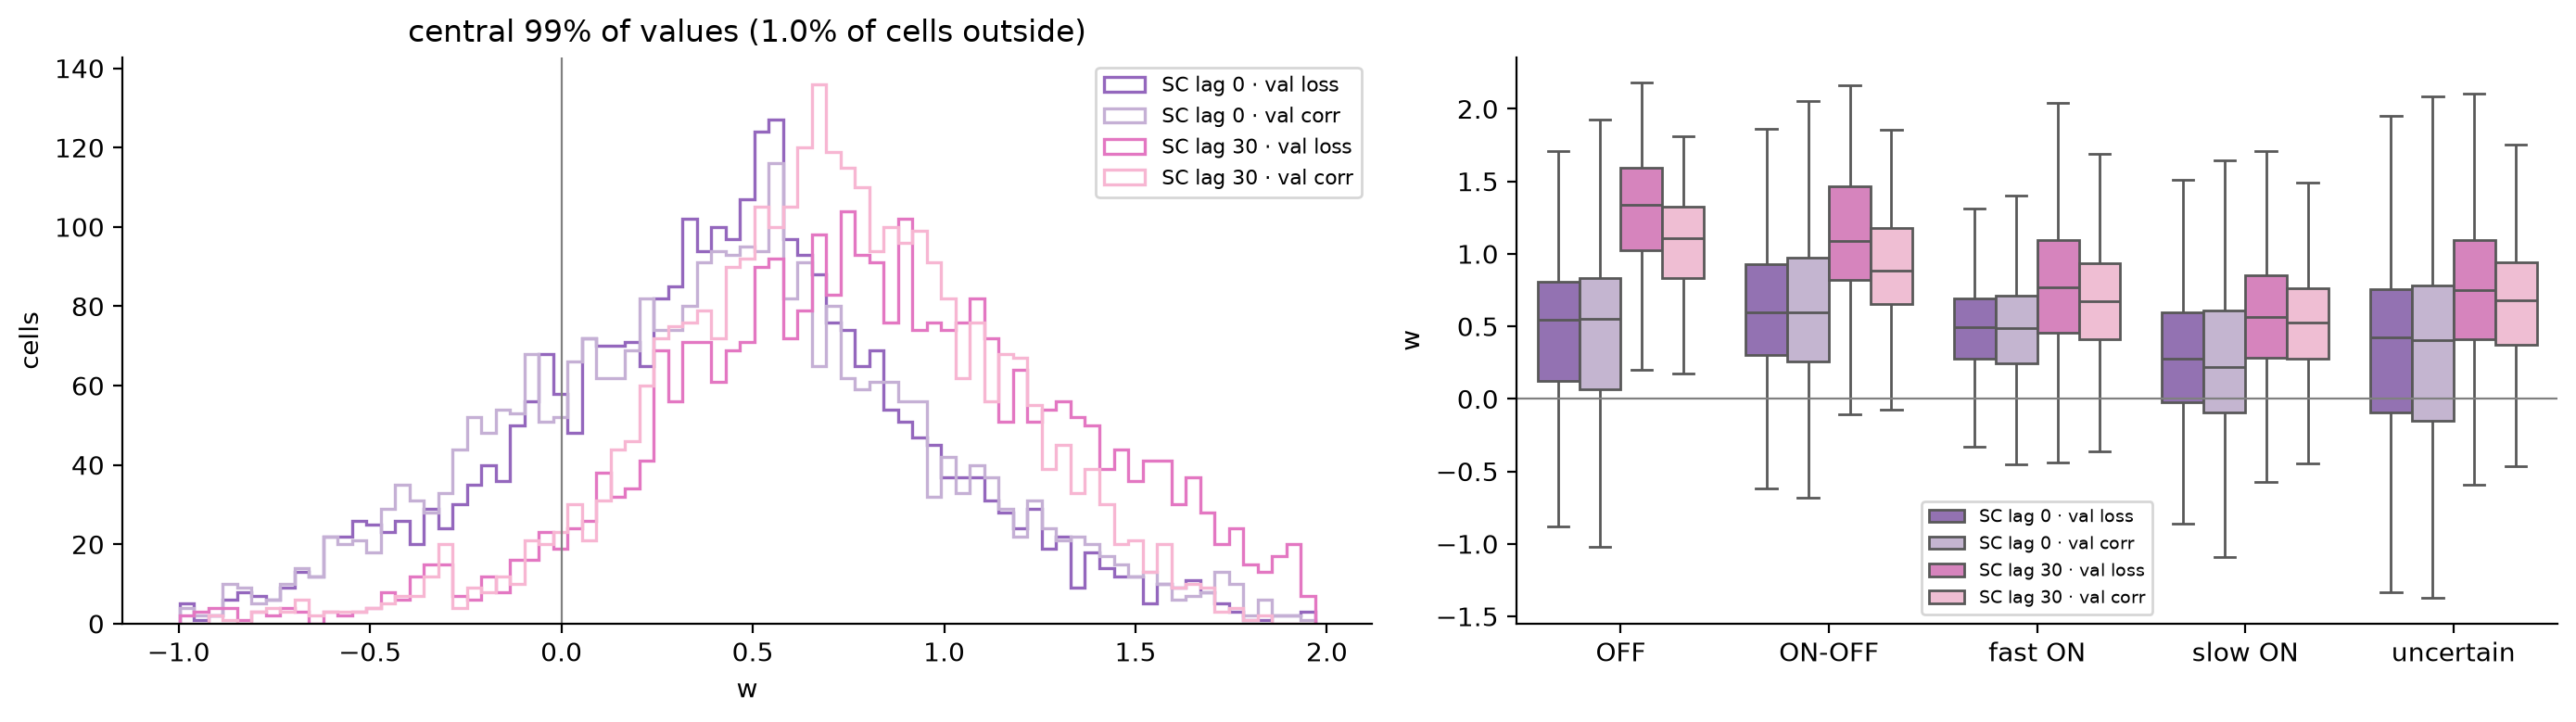

In [27]:
fig, axes = plt.subplots(ncols=2, figsize=(14, 4), gridspec_kw={"width_ratios": [1.2, 1]})
low, high = np.nanpercentile(w_wide.values, [0.5, 99.5])
bins = np.linspace(low, high, 80)
for label in w_wide:
    axes[0].hist(w_wide[label], bins=bins, histtype="step", lw=1.2, color=palette[label], label=label)
axes[0].axvline(0, color="0.5", lw=0.8)
outside = ((w_wide < low) | (w_wide > high)).mean().mean()
axes[0].set(xlabel="w", ylabel="cells", title=f"central 99% of values ({outside:.1%} of cells outside)")
axes[0].legend(fontsize=8)

cell_groups = metrics.drop_duplicates(["session", "neuron"]).set_index(["session", "neuron"])["group_class"]
w_by_group = w_long.join(cell_groups, on=["session", "neuron"])
sns.boxplot(data=w_by_group, x="group_class", y="w", hue="model", ax=axes[1], showfliers=False,
            palette={k: palette[k] for k in w_wide})
axes[1].axhline(0, color="0.5", lw=0.8)
axes[1].set(xlabel="", ylabel="w")
axes[1].legend(fontsize=7)
sns.despine(fig=fig)
fig.tight_layout()

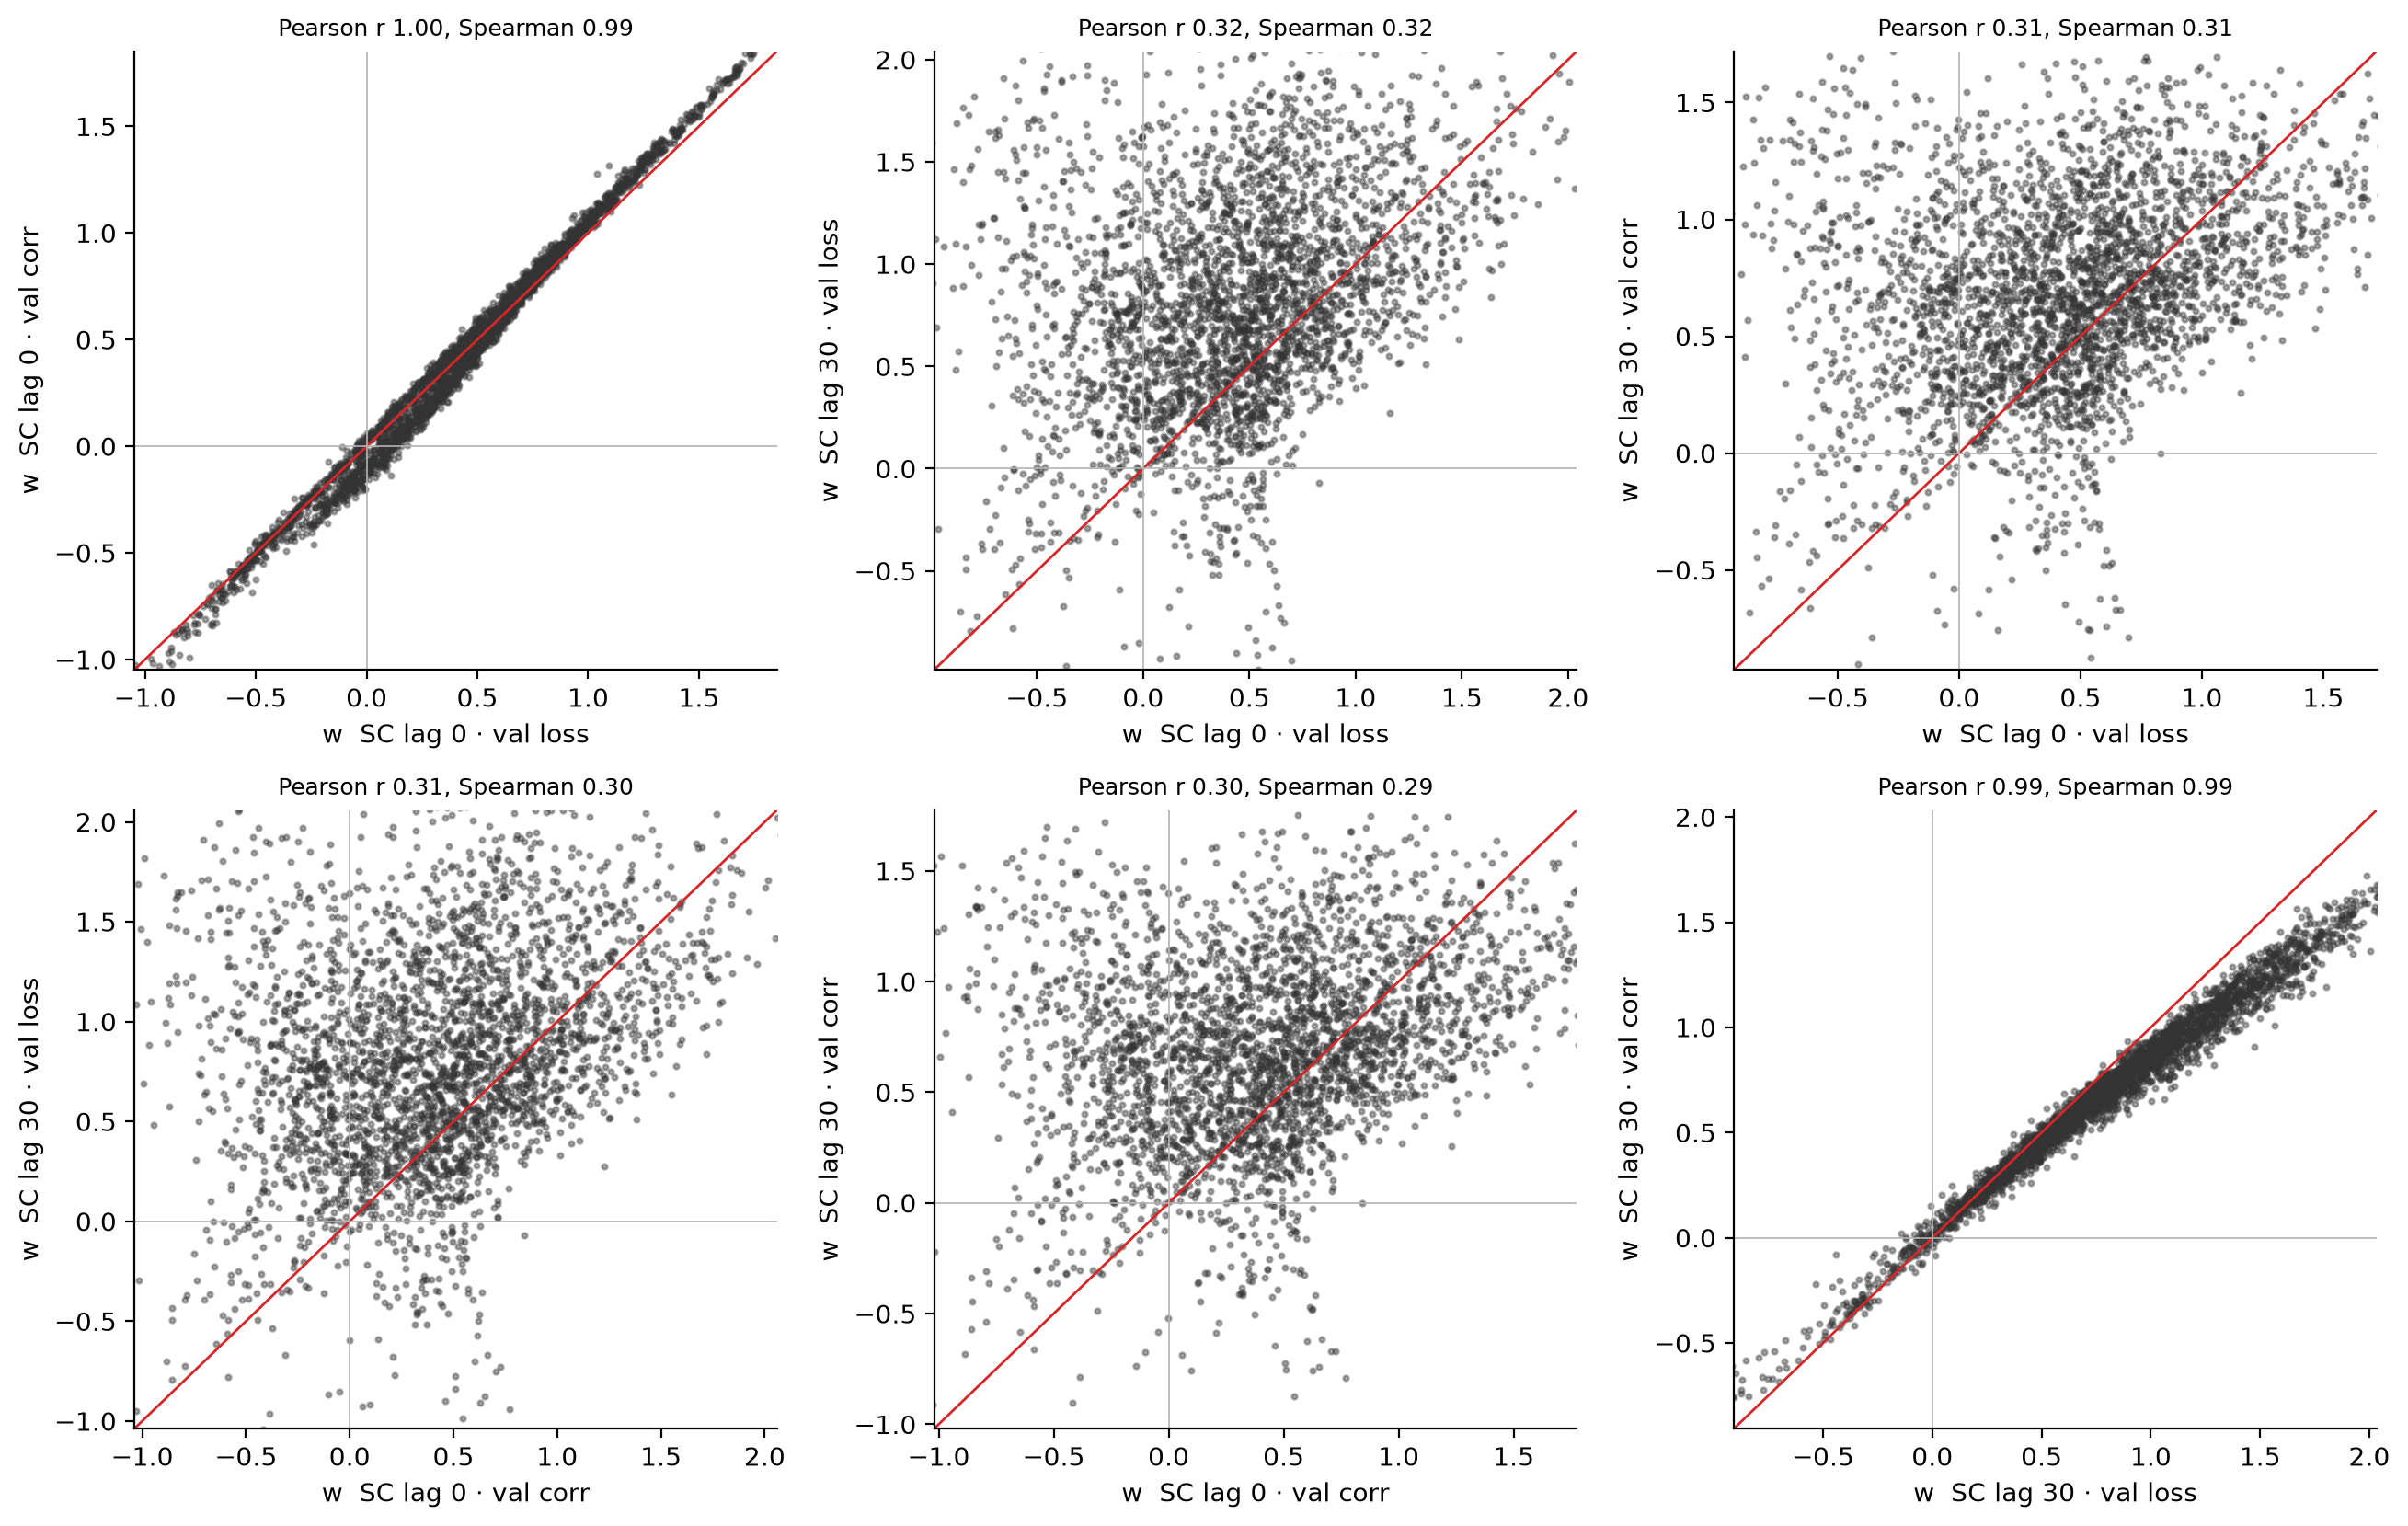

In [28]:
# Cell-by-cell comparison of w between every pair of Spatial Contrast models
pairs = list(itertools.combinations(w_wide.columns, 2))
n_cols = min(3, max(len(pairs), 1))
n_rows = int(np.ceil(len(pairs) / n_cols)) if pairs else 1
fig, axes = plt.subplots(nrows=n_rows, ncols=n_cols, figsize=(4.4 * n_cols, 4.2 * n_rows), squeeze=False)
for ax, (a, b) in zip(axes.flat, pairs):
    x, y = w_wide[a], w_wide[b]
    ax.scatter(x, y, s=4, alpha=0.4, color="0.2", rasterized=True)
    lo, hi = np.nanpercentile(np.r_[x, y], [0.5, 99.5])
    ax.plot([lo, hi], [lo, hi], color="tab:red", lw=1)
    ax.axhline(0, color="0.7", lw=0.6)
    ax.axvline(0, color="0.7", lw=0.6)
    ax.set(xlim=(lo, hi), ylim=(lo, hi), xlabel=f"w  {a}", ylabel=f"w  {b}")
    ax.set_title(f"Pearson r {pearsonr(x, y)[0]:.2f}, Spearman {spearmanr(x, y)[0]:.2f}", fontsize=9)
for ax in axes.flat[len(pairs) :]:
    ax.axis("off")
sns.despine(fig=fig)
fig.tight_layout()